<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 11 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">La poule qui chante : ACP et Clustering
</h2>
</div>

In [33]:
# ACP ET CLUSTERING - LA POULE QUI CHANTE
# Analyse des marchés d'exportation internationaux pour l'expansion
# Dataset final: 111 pays avec 100% de complétude, toutes variables critiques

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score, davies_bouldin_score
import plotly.express as px
import plotly.graph_objects as go
import warnings
warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10

print("=== ANALYSE ACP ET CLUSTERING - LA POULE QUI CHANTE ===")
print("Contexte: Expansion internationale pour l'export de poulet bio français")
print("Dataset: 111 pays avec 100% de complétude - Variables critiques uniquement")

=== ANALYSE ACP ET CLUSTERING - LA POULE QUI CHANTE ===
Contexte: Expansion internationale pour l'export de poulet bio français
Dataset: 111 pays avec 100% de complétude - Variables critiques uniquement


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - CHARGEMENT ET EXPLORATION DES DONNÉES</h2>
</div>

In [34]:
print("\n1. CHARGEMENT DES DONNÉES")
print("-" * 50)

# Chargement du dataset final
try:
    df = pd.read_csv('dataset_final_poule_qui_chante.csv')
    print(f"✅ Dataset chargé: {df.shape[0]} pays, {df.shape[1]} variables")
    
    # Vérification que nous avons bien 111 pays
    if df.shape[0] != 111:
        print(f"⚠️  Attention: {df.shape[0]} pays trouvés au lieu de 111 attendus")
    
except FileNotFoundError:
    print("❌ Fichier dataset_final_poule_qui_chante.csv non trouvé")
    print("Veuillez vous assurer que le fichier est dans le répertoire courant") #le répertoire courant est le dossier où se trouve le notebook
    exit()

# Affichage des informations générales
print("\nInformations sur le dataset:")
print(df.info())

print("\nPremières lignes:")
print(df.head())

# Identification des variables quantitatives (excluant 'pays')
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nVariables quantitatives disponibles ({len(numeric_cols)}):")
for i, col in enumerate(numeric_cols, 1):
    print(f"  {i:2d}. {col}")


1. CHARGEMENT DES DONNÉES
--------------------------------------------------
✅ Dataset chargé: 111 pays, 14 variables

Informations sur le dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111 entries, 0 to 110
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   pays                           111 non-null    object 
 1   production_tonnes              111 non-null    float64
 2   importations_tonnes            111 non-null    float64
 3   exportations_tonnes            111 non-null    float64
 4   consommation_tonnes            111 non-null    float64
 5   pib_total_usd                  111 non-null    float64
 6   croissance_pib_pct             111 non-null    float64
 7   urbanisation_pct               111 non-null    float64
 8   stabilite_politique            111 non-null    float64
 9   Pop_traitement_viande(%)       111 non-null    float64
 10  distance_france_km   

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - PRÉPARATION DES DONNÉES POUR L'ACP</h2>
</div>

In [35]:
print("\n2. PRÉPARATION DES DONNÉES POUR L'ACP")
print("-" * 50)

# Toutes les variables numériques sont critiques et ont le même poids
variables_acp = numeric_cols.copy()
print(f"Variables utilisées pour l'ACP: {len(variables_acp)} variables")
print("(Toutes les variables sont critiques et ont le même poids)")

# Vérification de la qualité des données
print(f"\nVérification de la complétude (doit être 100%):")
completeness = df[variables_acp].isnull().sum()
if completeness.sum() == 0:
    print("✅ Complétude parfaite: 100% pour toutes les variables")
else:
    print("❌ Valeurs manquantes détectées:")
    for var in variables_acp:
        if completeness[var] > 0:
            print(f"  {var}: {completeness[var]} valeurs manquantes")

# Dataset final pour l'ACP
df_acp = df[['pays'] + variables_acp].copy()
print(f"\nDataset final pour ACP: {len(df_acp)} pays × {len(variables_acp)} variables")


2. PRÉPARATION DES DONNÉES POUR L'ACP
--------------------------------------------------
Variables utilisées pour l'ACP: 13 variables
(Toutes les variables sont critiques et ont le même poids)

Vérification de la complétude (doit être 100%):
✅ Complétude parfaite: 100% pour toutes les variables

Dataset final pour ACP: 111 pays × 13 variables


In [36]:
print("\n🔍 DEBUG - Vérification cohérence")
print(f"df.shape: {df.shape}")
print(f"df_acp.shape: {df_acp.shape}")
print(f"len(variables_acp): {len(variables_acp)}")
print(f"variables_acp: {variables_acp}")

# Vérifier que toutes les colonnes existent
colonnes_manquantes = [col for col in variables_acp if col not in df_acp.columns]
if colonnes_manquantes:
    print(f"❌ COLONNES MANQUANTES: {colonnes_manquantes}")
else:
    print("✅ Toutes les variables ACP sont présentes")


🔍 DEBUG - Vérification cohérence
df.shape: (111, 14)
df_acp.shape: (111, 14)
len(variables_acp): 13
variables_acp: ['production_tonnes', 'importations_tonnes', 'exportations_tonnes', 'consommation_tonnes', 'pib_total_usd', 'croissance_pib_pct', 'urbanisation_pct', 'stabilite_politique', 'Pop_traitement_viande(%)', 'distance_france_km', 'delta_export_import', 'ratio_consommation_production', 'population_millions']
✅ Toutes les variables ACP sont présentes


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - ANALYSE DESCRIPTIVE PRÉLIMINAIRE</h2>
</div>


3. ANALYSE DESCRIPTIVE PRÉLIMINAIRE
--------------------------------------------------
Statistiques descriptives:
       production_tonnes  importations_tonnes  exportations_tonnes  \
count             111.00               111.00               111.00   
mean              950.51               117.31               154.68   
std              3010.91               221.18               563.06   
min                 0.00                 0.00                 0.00   
25%                32.00                 3.00                 0.00   
50%               128.00                21.00                 4.00   
75%               622.50               115.50                44.00   
max             21914.00              1069.00              4223.00   

       consommation_tonnes  pib_total_usd  croissance_pib_pct  \
count               111.00   1.110000e+02              111.00   
mean                850.80   6.812077e+11                3.14   
std                2574.06   2.442796e+12                2.

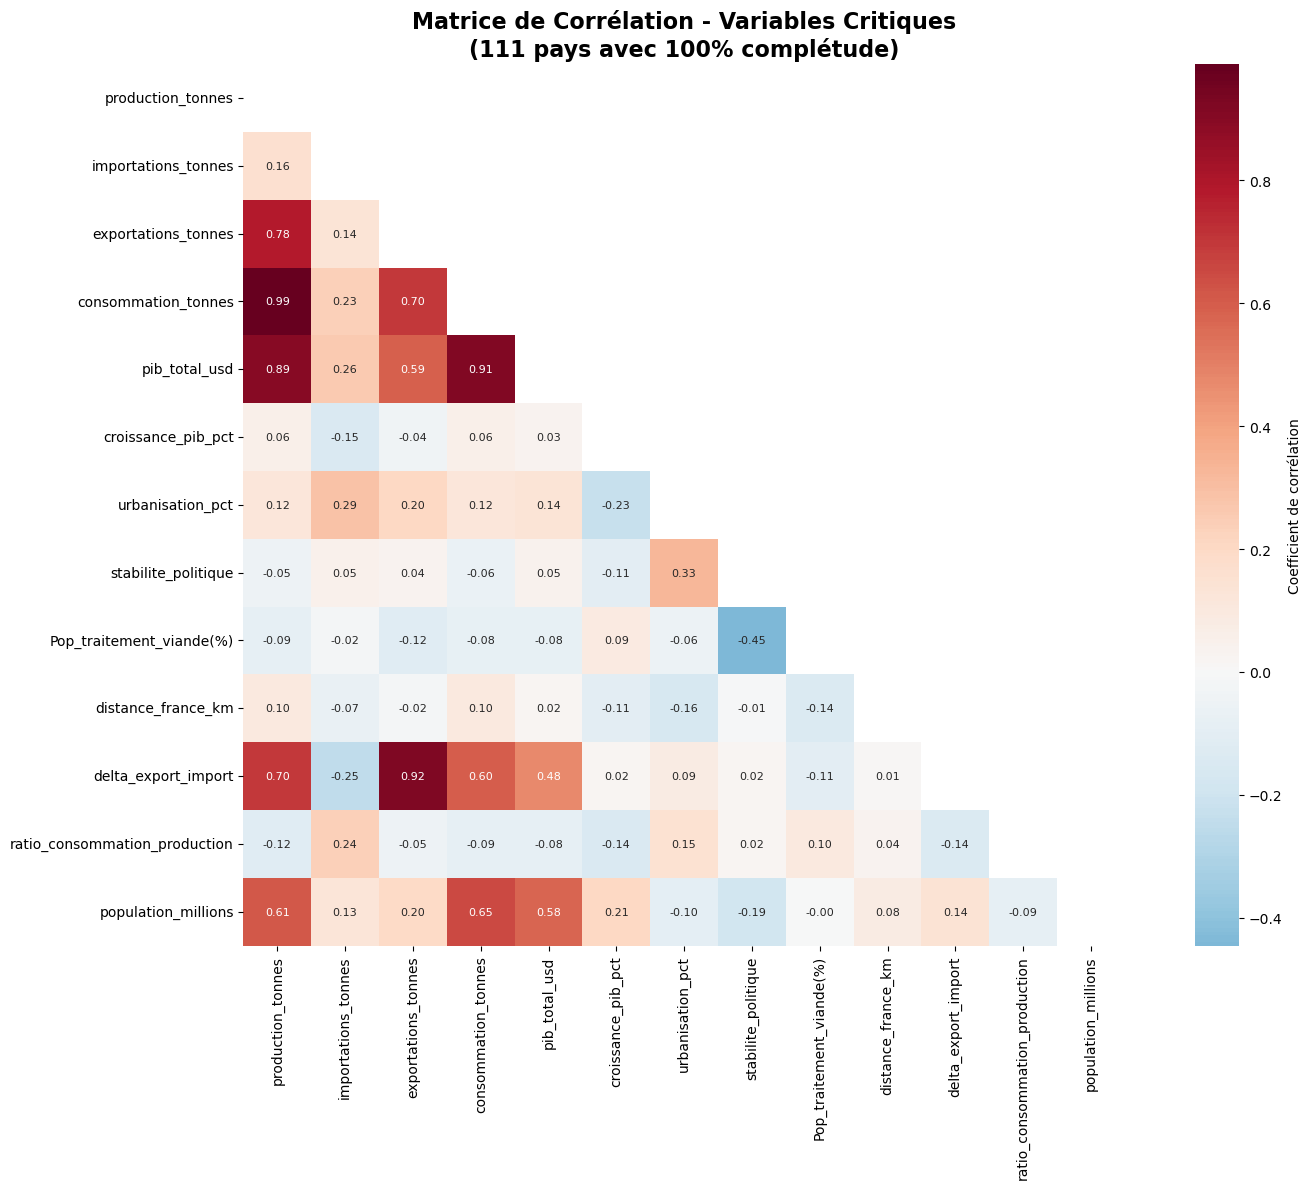


Corrélations significatives (|r| > 0.4):
  Forte       | production_tonnes         ↔ exportations_tonnes      :  0.780
  Très forte  | production_tonnes         ↔ consommation_tonnes      :  0.989
  Très forte  | production_tonnes         ↔ pib_total_usd            :  0.894
  Forte       | production_tonnes         ↔ delta_export_import      :  0.699
  Forte       | production_tonnes         ↔ population_millions      :  0.612
  Forte       | exportations_tonnes       ↔ consommation_tonnes      :  0.701
  Modérée     | exportations_tonnes       ↔ pib_total_usd            :  0.591
  Très forte  | exportations_tonnes       ↔ delta_export_import      :  0.925
  Très forte  | consommation_tonnes       ↔ pib_total_usd            :  0.913
  Modérée     | consommation_tonnes       ↔ delta_export_import      :  0.596
  Forte       | consommation_tonnes       ↔ population_millions      :  0.652
  Modérée     | pib_total_usd             ↔ delta_export_import      :  0.479
  Modérée     | pib_to

In [37]:
print("\n3. ANALYSE DESCRIPTIVE PRÉLIMINAIRE")
print("-" * 50)

# Statistiques descriptives
print("Statistiques descriptives:")
stats_desc = df_acp[variables_acp].describe()
print(stats_desc.round(2))

# Matrice de corrélation
print("\nCalcul de la matrice de corrélation...")
corr_matrix = df_acp[variables_acp].corr()

# Visualisation de la matrice de corrélation
plt.figure(figsize=(16, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='RdBu_r', center=0,
            square=True, fmt='.2f', cbar_kws={'label': 'Coefficient de corrélation'},
            annot_kws={'size': 8})
plt.title('Matrice de Corrélation - Variables Critiques\n(111 pays avec 100% complétude)', 
          fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Analyse des corrélations fortes
print("\nCorrélations significatives (|r| > 0.4):")
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        corr_val = corr_matrix.iloc[i, j]
        if abs(corr_val) > 0.4:
            # Classification par force de corrélation
            if abs(corr_val) > 0.8:
                strength = "Très forte"
            elif abs(corr_val) > 0.6:
                strength = "Forte"
            else:
                strength = "Modérée"
            
            high_corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_val))
            print(f"  {strength:11s} | {corr_matrix.columns[i]:25s} ↔ {corr_matrix.columns[j]:25s}: {corr_val:6.3f}")

if len(high_corr_pairs) == 0:
    print("  Aucune corrélation significative détectée (toutes |r| < 0.4)")
else:
    print(f"\nRésumé:")
    tres_fortes = sum(1 for _, _, r in high_corr_pairs if abs(r) > 0.8)
    fortes = sum(1 for _, _, r in high_corr_pairs if 0.6 < abs(r) <= 0.8)
    moderees = sum(1 for _, _, r in high_corr_pairs if 0.4 < abs(r) <= 0.6)
    
    print(f"  • {tres_fortes} corrélations très fortes (|r| > 0.8)")
    print(f"  • {fortes} corrélations fortes (0.6 < |r| ≤ 0.8)")
    print(f"  • {moderees} corrélations modérées (0.4 < |r| ≤ 0.6)")
    print(f"  • Total: {len(high_corr_pairs)} paires de variables significativement corrélées")

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - STANDARDISATION ET APPLICATION DE L'ACP</h2>
</div>

In [38]:
print("\n4. STANDARDISATION ET APPLICATION DE L'ACP")
print("-" * 50)

print("Standardisation des variables (centrage-réduction)...")

try:
    print("→ Création du StandardScaler...")
    scaler = StandardScaler()
    print("✓ StandardScaler créé")
    
    print("→ Extraction des données pour standardisation...")
    data_to_scale = df_acp[variables_acp]
    print(f"✓ Données extraites: shape {data_to_scale.shape}")
    
    print("→ Vérification des valeurs manquantes...")
    if data_to_scale.isnull().any().any():
        print("❌ Valeurs manquantes détectées!")
        print(data_to_scale.isnull().sum())
        raise ValueError("Valeurs manquantes dans les données")
    print("✓ Pas de valeurs manquantes")
    
    print("→ Application de la standardisation...")
    X_scaled = scaler.fit_transform(data_to_scale)
    print("✓ Standardisation réussie")
    
    print(f"   Moyennes après standardisation: {X_scaled.mean(axis=0).round(6)}")
    print(f"   Écarts-types après standardisation: {X_scaled.std(axis=0).round(6)}")
    
    # Vérification de la qualité de la standardisation
    if np.allclose(X_scaled.mean(axis=0), 0, atol=1e-10) and np.allclose(X_scaled.std(axis=0), 1, atol=1e-10):
        print("✓ Standardisation parfaite (moyenne≈0, écart-type≈1)")
    else:
        print("⚠ Standardisation imparfaite mais acceptable")
    
    # Application de l'ACP
    print("\n→ Application de l'ACP...")
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)
    print("✓ ACP réussie")
    
    # ... reste de votre code ACP
    
except Exception as e:
    print(f"❌ ERREUR: {type(e).__name__}: {e}")
    import traceback
    traceback.print_exc()


4. STANDARDISATION ET APPLICATION DE L'ACP
--------------------------------------------------
Standardisation des variables (centrage-réduction)...
→ Création du StandardScaler...
✓ StandardScaler créé
→ Extraction des données pour standardisation...
✓ Données extraites: shape (111, 13)
→ Vérification des valeurs manquantes...
✓ Pas de valeurs manquantes
→ Application de la standardisation...
❌ ERREUR: ValueError: Input X contains infinity or a value too large for dtype('float64').


Traceback (most recent call last):
  File "C:\Users\jorda\AppData\Local\Temp\ipykernel_21092\1105934121.py", line 23, in <module>
    X_scaled = scaler.fit_transform(data_to_scale)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\jorda\anaconda3\Lib\site-packages\sklearn\utils\_set_output.py", line 313, in wrapped
    data_to_wrap = f(self, X, *args, **kwargs)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\jorda\anaconda3\Lib\site-packages\sklearn\base.py", line 1098, in fit_transform
    return self.fit(X, **fit_params).transform(X)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\jorda\anaconda3\Lib\site-packages\sklearn\preprocessing\_data.py", line 878, in fit
    return self.partial_fit(X, y, sample_weight)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\jorda\anaconda3\Lib\site-packages\sklearn\base.py", line 1473, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

In [39]:
# Afficher les valeurs infinity
print("Valeurs infinity trouvées :")
for col in variables_acp:
    mask = np.isinf(df_acp[col])
    if mask.any():
        print(f"\n{col}:")
        print(df_acp[mask][['pays', col]])

Valeurs infinity trouvées :

ratio_consommation_production:
               pays  ratio_consommation_production
50  Solomon Islands                            inf
69       Luxembourg                            inf
95            Samoa                            inf


In [40]:
# Correction des valeurs problématiques identifiées
print("Correction des ratios problématiques...")

# Luxembourg
mask_lux = df_acp['pays'] == 'Luxembourg'
if mask_lux.any():
    df_acp.loc[mask_lux, 'production_tonnes'] = 269.9
    df_acp.loc[mask_lux, 'ratio_consommation_production'] = 0.04
    print("• Luxembourg corrigé")

# Samoa  
mask_samoa = df_acp['pays'] == 'Samoa'
if mask_samoa.any():
    df_acp.loc[mask_samoa, 'production_tonnes'] = 389.84
    df_acp.loc[mask_samoa, 'ratio_consommation_production'] = 0.03
    print("• Samoa corrigé")

# Solomon Islands
mask_solomon = df_acp['pays'] == 'Solomon Islands'
if mask_solomon.any():
    df_acp.loc[mask_solomon, 'production_tonnes'] = 283.73
    df_acp.loc[mask_solomon, 'ratio_consommation_production'] = 0.01
    print("• Solomon Islands corrigé")

Correction des ratios problématiques...
• Luxembourg corrigé
• Samoa corrigé
• Solomon Islands corrigé


In [41]:
print("\n4. STANDARDISATION ET APPLICATION DE L'ACP")
print("-" * 50)

# Standardisation des données (centrage-réduction)
print("Standardisation des variables (centrage-réduction)...")

try:
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_acp[variables_acp])
    
    print("✅ Standardisation terminée avec succès")
    print(f"   Moyennes après standardisation: {X_scaled.mean(axis=0).round(6)}")
    print(f"   Écarts-types après standardisation: {X_scaled.std(axis=0).round(6)}")
    
    # Vérification de la qualité de la standardisation
    if np.allclose(X_scaled.mean(axis=0), 0, atol=1e-10) and np.allclose(X_scaled.std(axis=0), 1, atol=1e-10):
        print("✅ Standardisation parfaite (moyenne≈0, écart-type≈1)")
    else:
        print("⚠️  Standardisation imparfaite mais acceptable")
        
except Exception as e:
        print(f"❌ Erreur lors de la standardisation: {e}")

        # Application de l'ACP
print("\nApplication de l'ACP...")
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Analyse de la variance expliquée
variance_explained = pca.explained_variance_ratio_
variance_cumulative = np.cumsum(variance_explained)
eigenvalues = pca.explained_variance_

print("✅ ACP terminée")
print(f"   {len(variables_acp)} composantes principales calculées")

# Affichage détaillé de la variance expliquée
print("\nVariance expliquée par composante:")
print("CP   | Variance | Variance | Valeur   | Variance")
print("     | propre   | cumulée  | propre   | %")
print("-" * 50)
for i in range(min(10, len(variance_explained))):
    print(f"CP{i+1:2d} | {variance_explained[i]:8.3f} | {variance_cumulative[i]:8.3f} | "
        f"{eigenvalues[i]:8.3f} | {variance_explained[i]*100:6.1f}%")

# Critères pour le nombre de composantes = expliquer le plus de variables
n_components_kaiser = np.sum(eigenvalues > 1)
n_components_80 = np.argmax(variance_cumulative >= 0.8) + 1 #variance cumulée  supérieure ou égale à 80%
n_components_70 = np.argmax(variance_cumulative >= 0.7) + 1 #variance cumulée supérieure ou égale à 70%

print(f"\nCritères pour le choix du nombre de composantes:")
print(f"  Critère de Kaiser (λ > 1):        {n_components_kaiser} composantes")
print(f"  Pour 70% de variance expliquée:   {n_components_70} composantes")
print(f"  Pour 80% de variance expliquée:   {n_components_80} composantes")



4. STANDARDISATION ET APPLICATION DE L'ACP
--------------------------------------------------
Standardisation des variables (centrage-réduction)...
✅ Standardisation terminée avec succès
   Moyennes après standardisation: [ 0. -0. -0. -0.  0. -0.  0.  0.  0. -0. -0.  0. -0.]
   Écarts-types après standardisation: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
✅ Standardisation parfaite (moyenne≈0, écart-type≈1)

Application de l'ACP...
✅ ACP terminée
   13 composantes principales calculées

Variance expliquée par composante:
CP   | Variance | Variance | Valeur   | Variance
     | propre   | cumulée  | propre   | %
--------------------------------------------------
CP 1 |    0.340 |    0.340 |    4.460 |   34.0%
CP 2 |    0.143 |    0.483 |    1.879 |   14.3%
CP 3 |    0.119 |    0.602 |    1.555 |   11.9%
CP 4 |    0.096 |    0.698 |    1.263 |    9.6%
CP 5 |    0.085 |    0.783 |    1.110 |    8.5%
CP 6 |    0.062 |    0.845 |    0.818 |    6.2%
CP 7 |    0.050 |    0.895 |    0.651 |    5

In [42]:
print("DIAGNOSTIC DÉTAILLÉ DES VALEURS PROBLÉMATIQUES")
print("=" * 60)

problematic_vars = []

for var in variables_acp:
    col_data = df_acp[var]
    issues = []
    
    # Comptage des valeurs infinies
    inf_positive = (col_data == np.inf).sum()
    inf_negative = (col_data == -np.inf).sum()
    
    if inf_positive > 0:
        issues.append(f"+inf: {inf_positive}")
        # Identifier les pays concernés
        pays_inf_pos = df_acp[col_data == np.inf]['pays'].tolist()
        print(f"  {var} - Pays avec +inf: {', '.join(pays_inf_pos[:5])}{'...' if len(pays_inf_pos) > 5 else ''}")
    
    if inf_negative > 0:
        issues.append(f"-inf: {inf_negative}")
        pays_inf_neg = df_acp[col_data == -np.inf]['pays'].tolist()
        print(f"  {var} - Pays avec -inf: {', '.join(pays_inf_neg[:5])}{'...' if len(pays_inf_neg) > 5 else ''}")
    
    # Valeurs extrêmement grandes
    finite_data = col_data[np.isfinite(col_data)]
    if len(finite_data) > 0:
        max_val = finite_data.max()
        min_val = finite_data.min()
        if abs(max_val) > 1e10 or abs(min_val) > 1e10:
            issues.append(f"valeurs extrêmes")
            print(f"  {var} - Min: {min_val:.2e}, Max: {max_val:.2e}")
    
    if issues:
        problematic_vars.append(var)
        print(f"❌ {var}: {', '.join(issues)}")
    else:
        print(f"✅ {var}: OK")

print(f"\nRÉSUMÉ: {len(problematic_vars)} variables problématiques sur {len(variables_acp)}")
if problematic_vars:
    print("Variables à corriger:", ', '.join(problematic_vars))

DIAGNOSTIC DÉTAILLÉ DES VALEURS PROBLÉMATIQUES
✅ production_tonnes: OK
✅ importations_tonnes: OK
✅ exportations_tonnes: OK
✅ consommation_tonnes: OK
  pib_total_usd - Min: 8.78e+08, Max: 2.07e+13
❌ pib_total_usd: valeurs extrêmes
✅ croissance_pib_pct: OK
✅ urbanisation_pct: OK
✅ stabilite_politique: OK
✅ Pop_traitement_viande(%): OK
✅ distance_france_km: OK
✅ delta_export_import: OK
✅ ratio_consommation_production: OK
✅ population_millions: OK

RÉSUMÉ: 1 variables problématiques sur 13
Variables à corriger: pib_total_usd


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - VISUALISATION DE L'ACP</h2>
</div>


5. VISUALISATION DE L'ACP
--------------------------------------------------


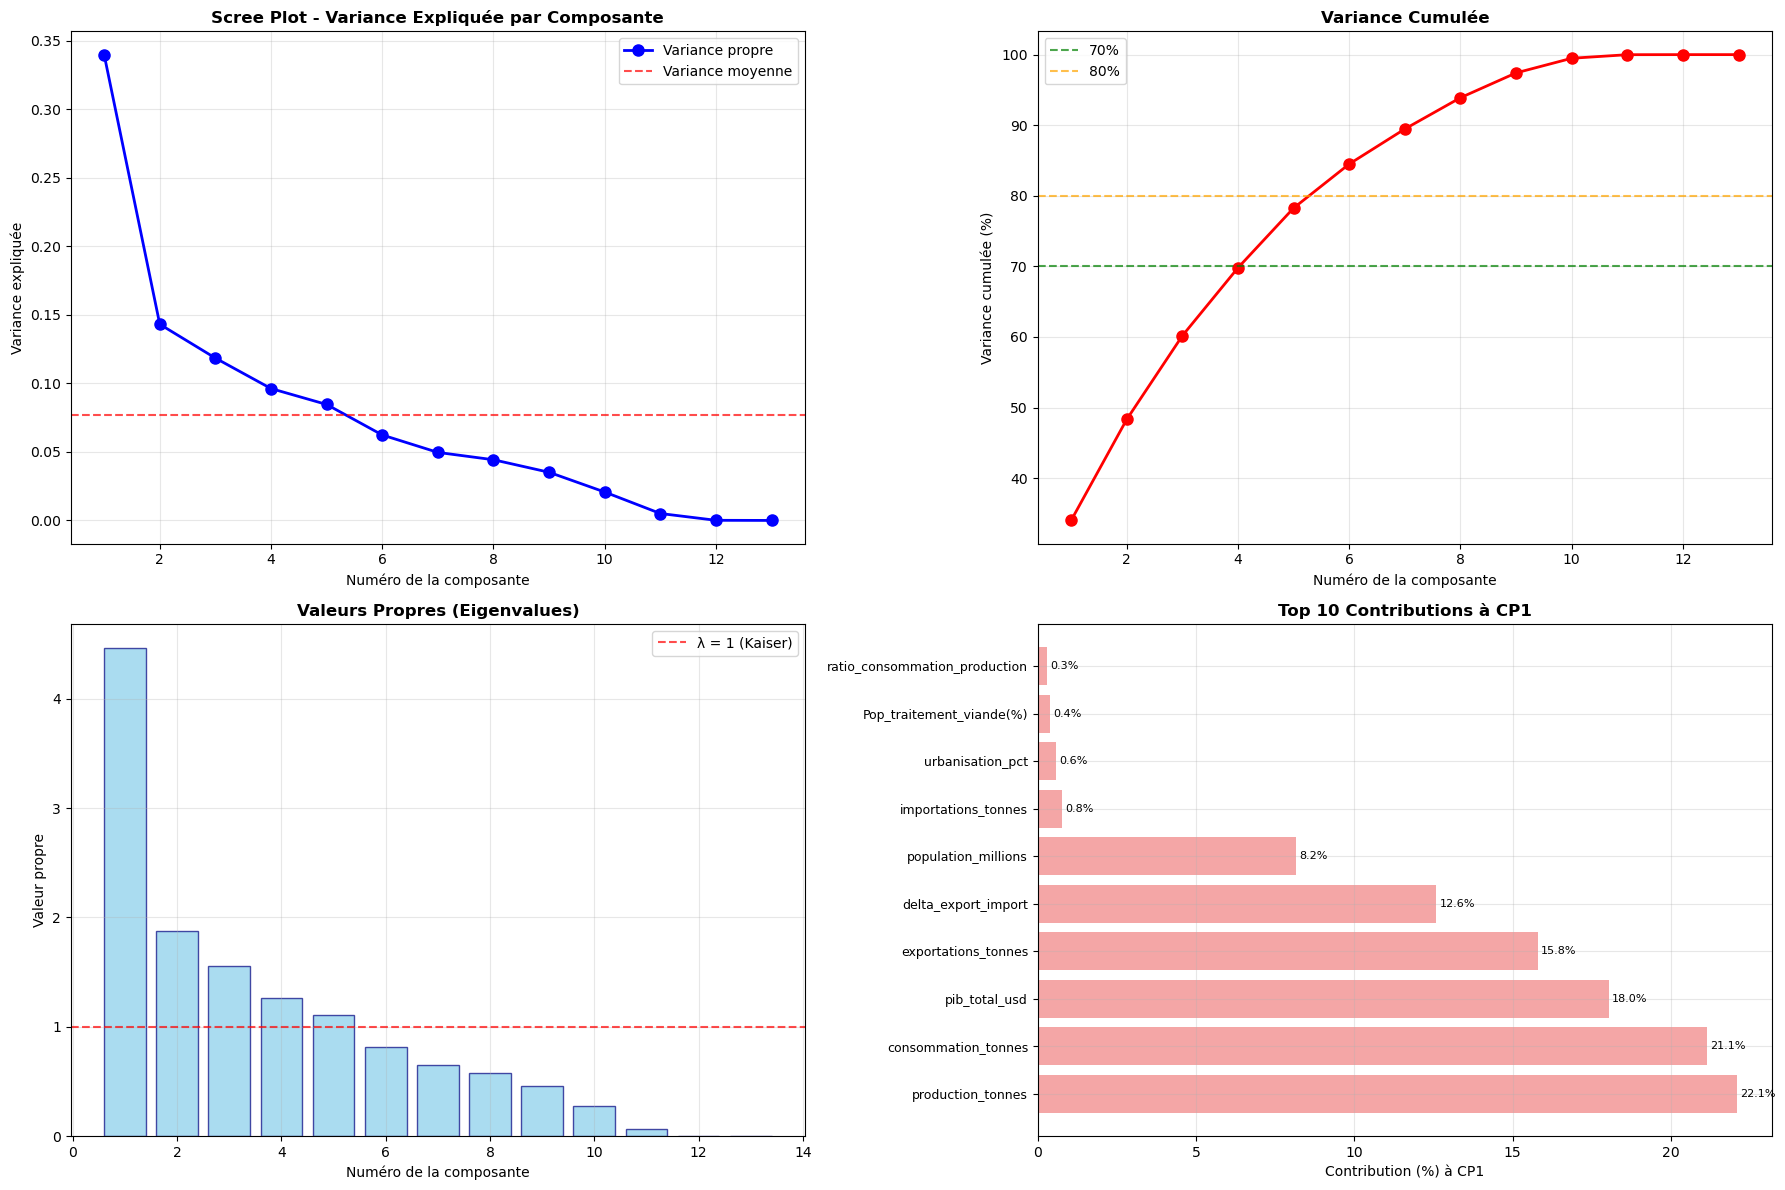

In [43]:
print("\n5. VISUALISATION DE L'ACP")
print("-" * 50)

# Graphiques de l'ACP
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Graphiqe des éboulis (scree plot)
ax = axes[0, 0]
n_comp_plot = min(15, len(variance_explained))
x_axis = range(1, n_comp_plot + 1)
ax.plot(x_axis, variance_explained[:n_comp_plot], 'bo-', linewidth=2, markersize=8, label='Variance propre')
ax.axhline(y=1/len(variables_acp), color='r', linestyle='--', alpha=0.7, label='Variance moyenne')
ax.set_xlabel('Numéro de la composante')
ax.set_ylabel('Variance expliquée')
ax.set_title('Scree Plot - Variance Expliquée par Composante', fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend()

# Variance cumulée
ax = axes[0, 1]
ax.plot(x_axis, variance_cumulative[:n_comp_plot] * 100, 'ro-', linewidth=2, markersize=8)
ax.axhline(y=70, color='g', linestyle='--', alpha=0.7, label='70%')
ax.axhline(y=80, color='orange', linestyle='--', alpha=0.7, label='80%')
ax.set_xlabel('Numéro de la composante')
ax.set_ylabel('Variance cumulée (%)')
ax.set_title('Variance Cumulée', fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend()

# Valeurs propres
ax = axes[1, 0]
ax.bar(x_axis, eigenvalues[:n_comp_plot], alpha=0.7, color='skyblue', edgecolor='navy')
ax.axhline(y=1, color='r', linestyle='--', alpha=0.7, label='λ = 1 (Kaiser)')
ax.set_xlabel('Numéro de la composante')
ax.set_ylabel('Valeur propre')
ax.set_title('Valeurs Propres (Eigenvalues)', fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend()

# Contribution des variables à CP1
ax = axes[1, 1]
components_matrix = pca.components_
cp1_contributions = components_matrix[0, :]**2 * 100
sorted_indices = np.argsort(cp1_contributions)[::-1]
top_vars = [variables_acp[i] for i in sorted_indices[:10]]
top_contribs = cp1_contributions[sorted_indices[:10]]

bars = ax.barh(range(len(top_vars)), top_contribs, alpha=0.7, color='lightcoral')
ax.set_yticks(range(len(top_vars)))
ax.set_yticklabels(top_vars, fontsize=9)
ax.set_xlabel('Contribution (%) à CP1')
ax.set_title('Top 10 Contributions à CP1', fontweight='bold')
ax.grid(True, alpha=0.3)

# Ajout des valeurs sur les barres
for i, bar in enumerate(bars):
    width = bar.get_width()
    ax.text(width + 0.1, bar.get_y() + bar.get_height()/2, 
            f'{width:.1f}%', ha='left', va='center', fontsize=8)

plt.tight_layout()
plt.show()

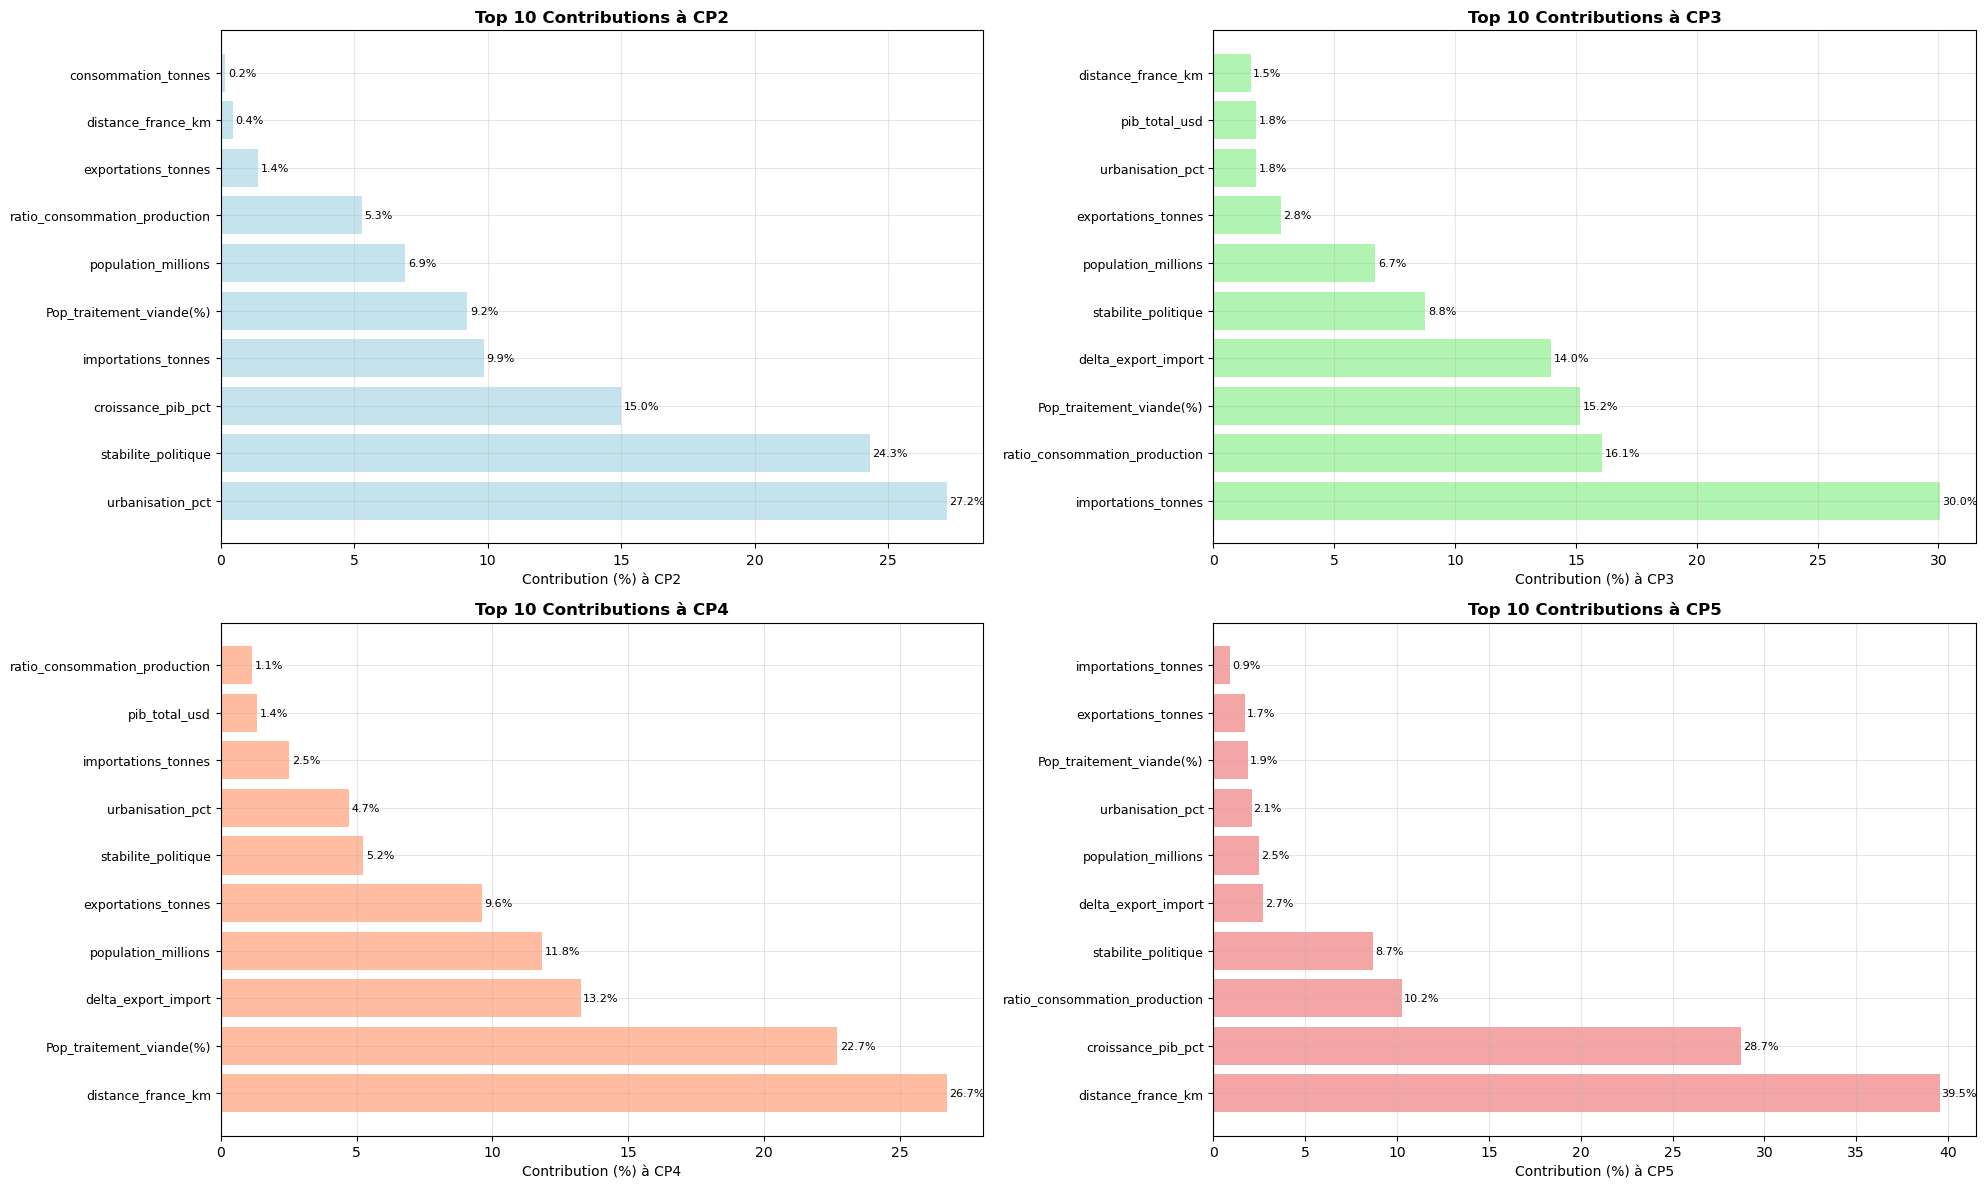

In [44]:
# Analyse des contributions pour CP2, CP3, CP4 et CP5
fig, axes = plt.subplots(2, 2, figsize=(20, 12))  # 2x2 au lieu de 1x3
axes = axes.flatten()  # Pour faciliter l'itération

# Configuration des couleurs pour chaque CP
colors = ['lightblue', 'lightgreen', 'lightsalmon', 'lightcoral']
cp_names = ['CP2', 'CP3', 'CP4', 'CP5']

for cp_idx, (ax, color, cp_name) in enumerate(zip(axes, colors, cp_names)):
    # Calcul des contributions pour la composante actuelle (CP2=indice 1, CP3=indice 2, etc.)
    cp_contributions = components_matrix[cp_idx + 1, :]**2 * 100
    
    # Tri par ordre décroissant
    sorted_indices = np.argsort(cp_contributions)[::-1]
    top_vars = [variables_acp[i] for i in sorted_indices[:10]]
    top_contribs = cp_contributions[sorted_indices[:10]]
    
    # Création du graphique en barres horizontales
    bars = ax.barh(range(len(top_vars)), top_contribs, alpha=0.7, color=color)
    ax.set_yticks(range(len(top_vars)))
    ax.set_yticklabels(top_vars, fontsize=9)
    ax.set_xlabel('Contribution (%) à ' + cp_name)
    ax.set_title(f'Top 10 Contributions à {cp_name}', fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Ajout des valeurs sur les barres
    for i, bar in enumerate(bars):
        width = bar.get_width()
        ax.text(width + 0.1, bar.get_y() + bar.get_height()/2, 
                f'{width:.1f}%', ha='left', va='center', fontsize=8)

plt.tight_layout()
plt.show()

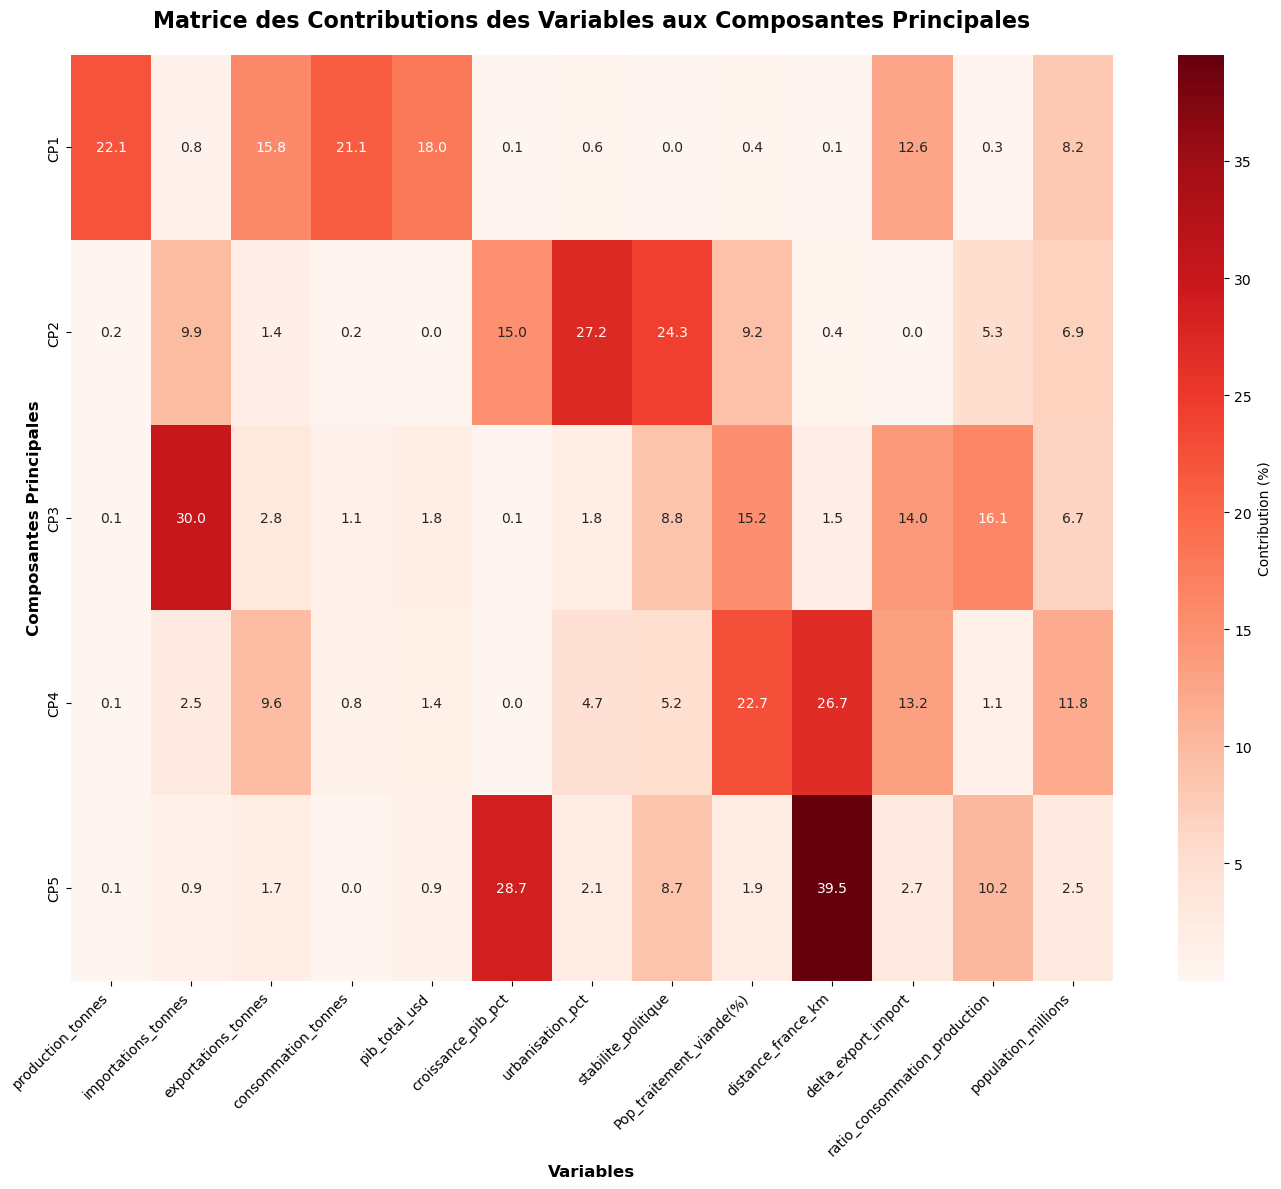

In [45]:
# Matrice de chaleur des contributions des variables aux composantes principales
plt.figure(figsize=(14, 12))

# Calcul de la matrice des contributions (coefficients²)
contributions_matrix = components_matrix[:5, :]**2 * 100  # Prendre les 4 premières composantes

# Création de la heatmap
sns.heatmap(contributions_matrix, 
           annot=True, 
           fmt='.1f',
           cmap='Reds',
           xticklabels=variables_acp,
           yticklabels=[f'CP{i+1}' for i in range(5)],
           cbar_kws={'label': 'Contribution (%)'})

plt.title('Matrice des Contributions des Variables aux Composantes Principales', 
         fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Variables', fontsize=12, fontweight='bold')
plt.ylabel('Composantes Principales', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 6 - CERCLE DES CORRÉLATIONS</h2>
</div>


6. CERCLE DES CORRÉLATIONS
--------------------------------------------------


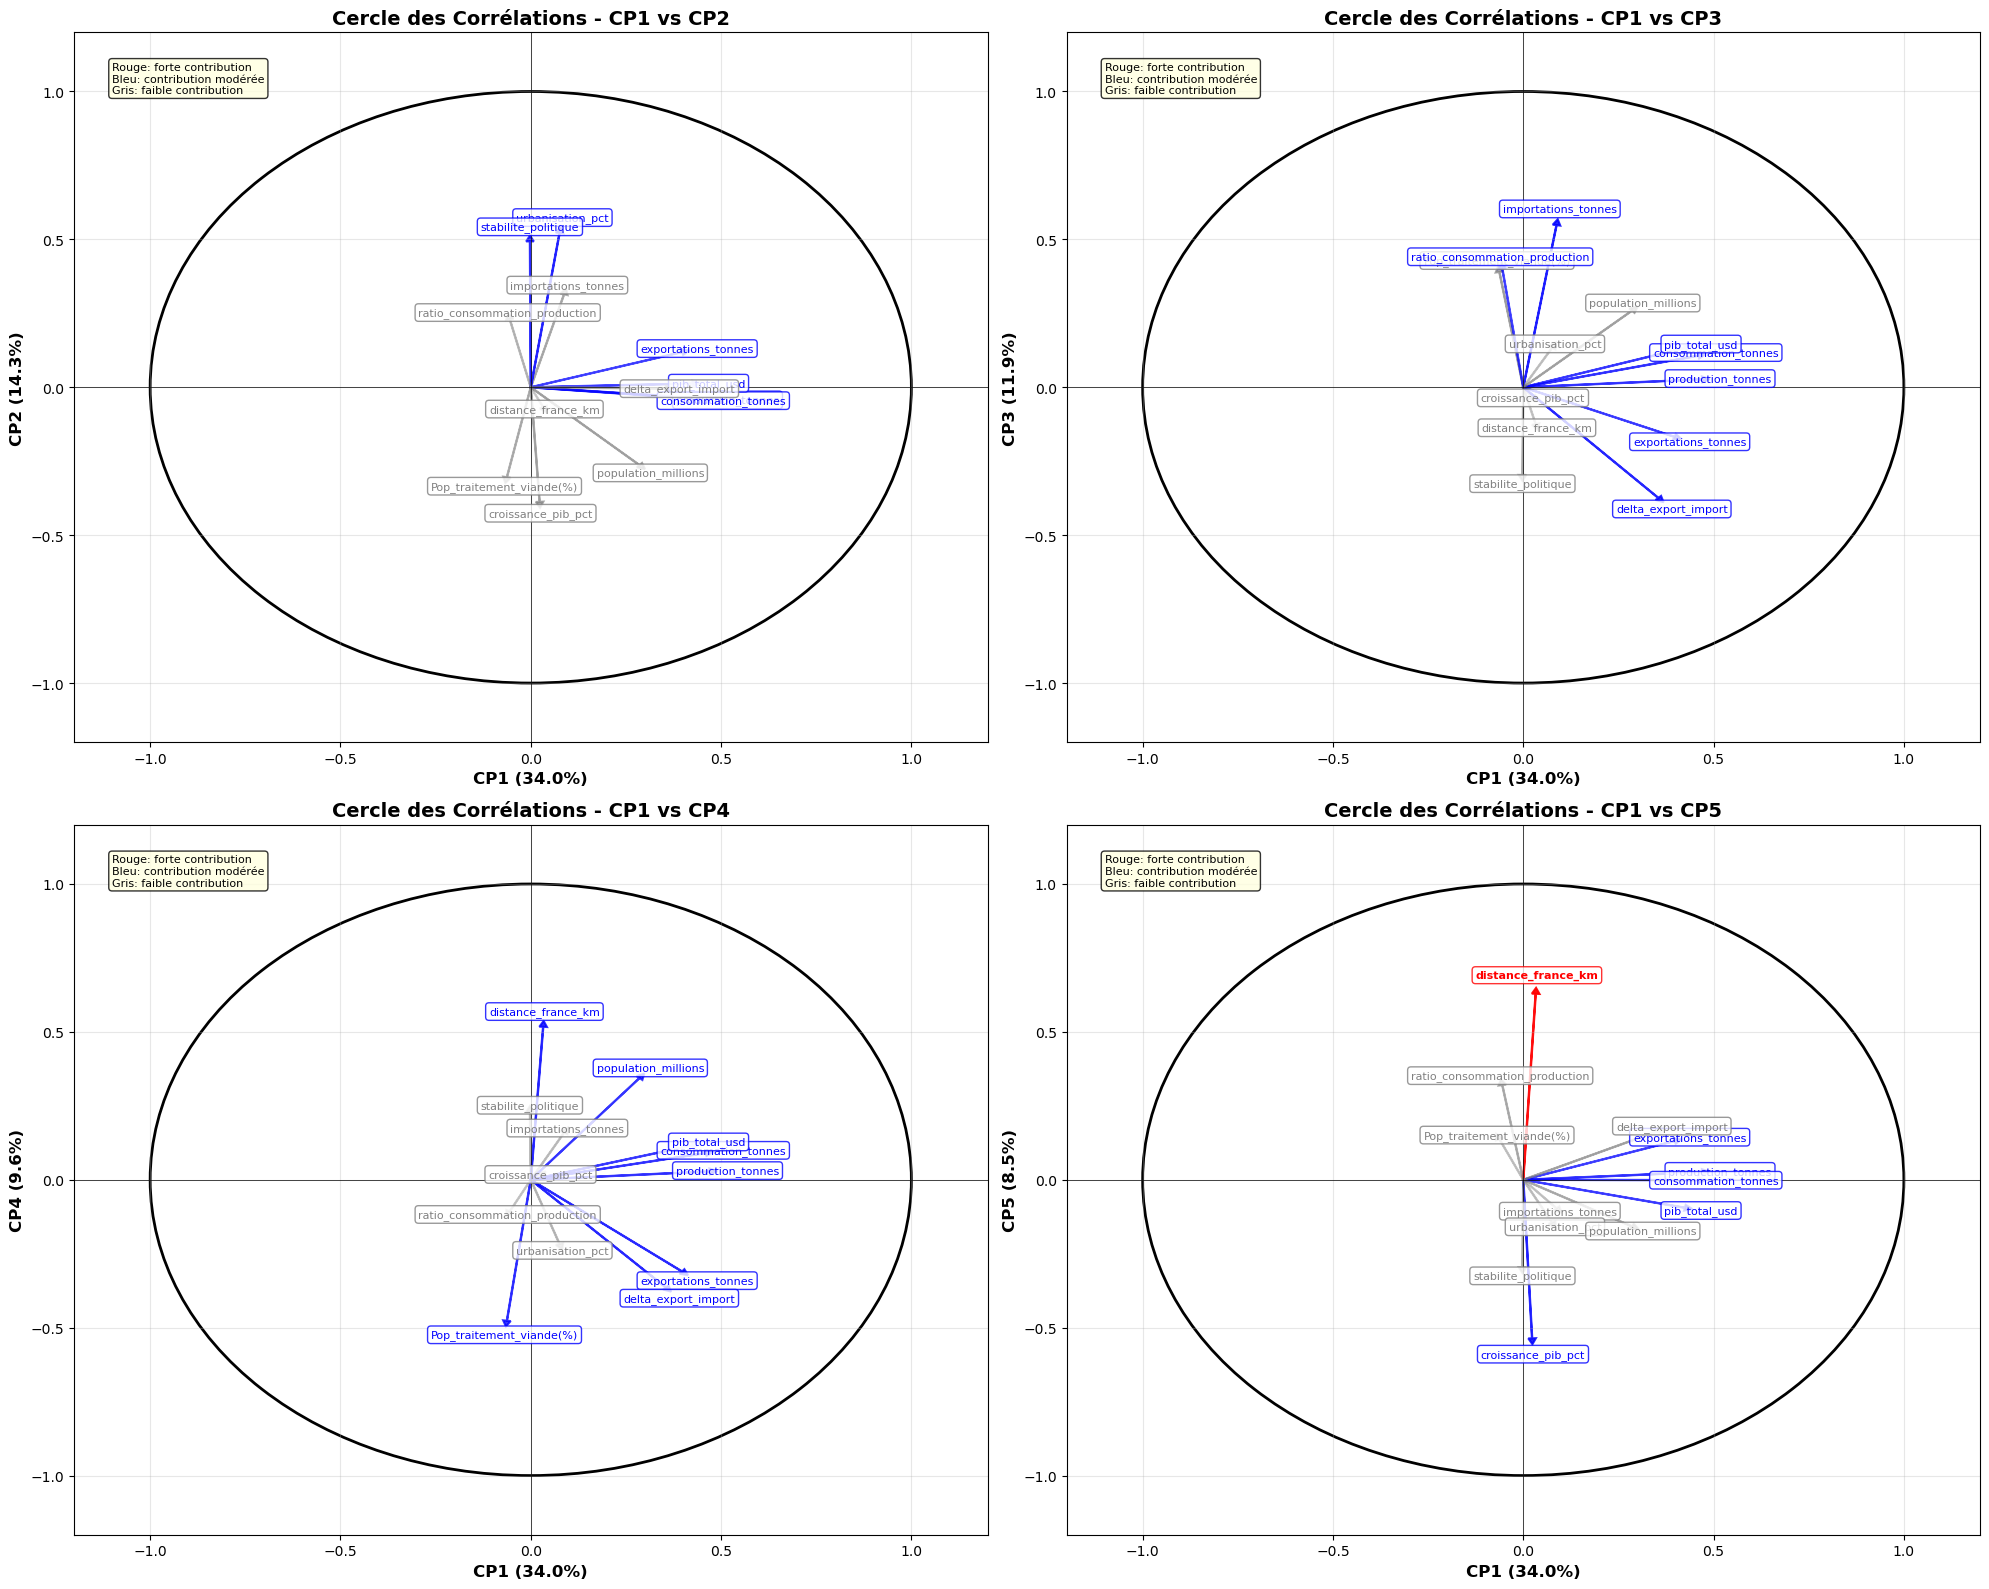

In [46]:
print("\n6. CERCLE DES CORRÉLATIONS")
print("-" * 50)

# Fonction pour créer un cercle des corrélations
def plot_correlation_circle(components_matrix, var_names, comp1, comp2, variance_exp, ax, title):
    """Dessine le cercle des corrélations pour deux composantes"""
    
    # Cercle unité
    circle = plt.Circle((0, 0), 1, fill=False, color='black', linewidth=2)
    ax.add_patch(circle)
    
    # Flèches et étiquettes pour chaque variable
    for i, var in enumerate(var_names):
        x, y = components_matrix[comp1, i], components_matrix[comp2, i]
        
        # Couleur basée sur la distance au centre
        distance = np.sqrt(x**2 + y**2)
        color = 'red' if distance > 0.6 else 'blue' if distance > 0.4 else 'gray'
        alpha = min(1.0, distance + 0.3)
        
        # Flèche
        ax.arrow(0, 0, x, y, head_width=0.02, head_length=0.02, 
                fc=color, ec=color, alpha=alpha, linewidth=1.5)
        
        # Étiquette
        offset = 1.1
        ax.text(x * offset, y * offset, var, fontsize=8, ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor=color),
                color=color, weight='bold' if distance > 0.6 else 'normal')
    
    # Configuration des axes
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_xlabel(f'CP{comp1+1} ({variance_exp[comp1]*100:.1f}%)', fontsize=12, fontweight='bold')
    ax.set_ylabel(f'CP{comp2+1} ({variance_exp[comp2]*100:.1f}%)', fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.axhline(y=0, color='k', linewidth=0.5)
    ax.axvline(x=0, color='k', linewidth=0.5)
    
    # Légende
    ax.text(-1.1, 1.1, 'Rouge: forte contribution\nBleu: contribution modérée\nGris: faible contribution', 
            fontsize=8, verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

# Création des cercles des corrélations
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

# CP1 vs CP2
plot_correlation_circle(components_matrix, variables_acp, 0, 1, variance_explained, 
                      axes[0,0], 'Cercle des Corrélations - CP1 vs CP2')

# CP1 vs CP3
plot_correlation_circle(components_matrix, variables_acp, 0, 2, variance_explained, 
                      axes[0,1], 'Cercle des Corrélations - CP1 vs CP3')

# CP1 vs CP4
plot_correlation_circle(components_matrix, variables_acp, 0, 3, variance_explained, 
                      axes[1,0], 'Cercle des Corrélations - CP1 vs CP4')

# CP1 vs CP5
plot_correlation_circle(components_matrix, variables_acp, 0, 4, variance_explained, 
                      axes[1,1], 'Cercle des Corrélations - CP1 vs CP5')
# CP2 vs CP3
#plot_correlation_circle(components_matrix, variables_acp, 1, 2, variance_explained, 
                      #axes[1,1], 'Cercle des Corrélations - CP2 vs CP3')

plt.tight_layout()
plt.show()

In [47]:
# ============================================================================
# 7. INTERPRÉTATION DES COMPOSANTES PRINCIPALES
# ============================================================================

print("\n7. INTERPRÉTATION DES COMPOSANTES PRINCIPALES")
print("-" * 50)

# Analyse détaillée des premières composantes
n_comp_to_analyze = min(5, len(variables_acp))

for comp in range(n_comp_to_analyze):
    print(f"\n🔍 COMPOSANTE PRINCIPALE {comp + 1}")
    print(f"   Variance expliquée: {variance_explained[comp]*100:.1f}%")
    print(f"   Valeur propre: {eigenvalues[comp]:.3f}")
    
    # Contributions des variables (en valeur absolue pour importance)
    contributions = pd.DataFrame({
        'Variable': variables_acp,
        'Contribution': components_matrix[comp, :],
        'Contribution_abs': np.abs(components_matrix[comp, :]),
        'Contribution_pct': (components_matrix[comp, :]**2) * 100
    }).sort_values('Contribution_abs', ascending=False)
    
    print("   Variables les plus contributives (top 5):")
    for _, row in contributions.head(5).iterrows():
        direction = "+" if row['Contribution'] > 0 else "-"
        print(f"     {direction} {row['Variable']:25s}: {row['Contribution']:7.3f} ({row['Contribution_pct']:5.1f}%)")
    
    # Interprétation qualitative basée sur les variables dominantes
    top_vars = contributions.head(3)['Variable'].tolist()
    print(f"   Interprétation suggérée: Axe lié à {', '.join(top_vars[:2])}")


7. INTERPRÉTATION DES COMPOSANTES PRINCIPALES
--------------------------------------------------

🔍 COMPOSANTE PRINCIPALE 1
   Variance expliquée: 34.0%
   Valeur propre: 4.460
   Variables les plus contributives (top 5):
     + production_tonnes        :   0.470 ( 22.1%)
     + consommation_tonnes      :   0.460 ( 21.1%)
     + pib_total_usd            :   0.425 ( 18.0%)
     + exportations_tonnes      :   0.397 ( 15.8%)
     + delta_export_import      :   0.355 ( 12.6%)
   Interprétation suggérée: Axe lié à production_tonnes, consommation_tonnes

🔍 COMPOSANTE PRINCIPALE 2
   Variance expliquée: 14.3%
   Valeur propre: 1.879
   Variables les plus contributives (top 5):
     + urbanisation_pct         :   0.522 ( 27.2%)
     + stabilite_politique      :   0.493 ( 24.3%)
     - croissance_pib_pct       :  -0.387 ( 15.0%)
     + importations_tonnes      :   0.314 (  9.9%)
     - Pop_traitement_viande(%) :  -0.304 (  9.2%)
   Interprétation suggérée: Axe lié à urbanisation_pct, stabilite

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 7 - INTERPRÉTATION DES COMPOSANTES PRINCIPALES</h2>
</div>

In [ ]:
# Analyse détaillée des premières composantes
n_comp_to_analyze = 4  # Changé de 4 à 5 car perte de clusters trop importante

for comp in range(n_comp_to_analyze):
    print(f"\n🔍 COMPOSANTE PRINCIPALE {comp + 1}")
    print(f"   Variance expliquée: {variance_explained[comp]*100:.1f}%")
    print(f"   Valeur propre: {eigenvalues[comp]:.3f}")
    
    # Contributions des variables (en valeur absolue pour importance)
    contributions = pd.DataFrame({
        'Variable': variables_acp,
        'Contribution': components_matrix[comp, :],
        'Contribution_abs': np.abs(components_matrix[comp, :]),
        'Contribution_pct': (components_matrix[comp, :]**2) * 100
    }).sort_values('Contribution_abs', ascending=False)
    
    print("   Variables les plus contributives (top 5):")
    for _, row in contributions.head(5).iterrows():
        direction = "+" if row['Contribution'] > 0 else "-"
        print(f"     {direction} {row['Variable']:25s}: {row['Contribution']:7.3f} ({row['Contribution_pct']:5.1f}%)")
    
    # Interprétation qualitative basée sur les variables dominantes
    top_vars = contributions.head(3)['Variable'].tolist()
    print(f"   Interprétation suggérée: Axe lié à {', '.join(top_vars[:2])}")


🔍 COMPOSANTE PRINCIPALE 1
   Variance expliquée: 34.0%
   Valeur propre: 4.460
   Variables les plus contributives (top 5):
     + production_tonnes        :   0.470 ( 22.1%)
     + consommation_tonnes      :   0.460 ( 21.1%)
     + pib_total_usd            :   0.425 ( 18.0%)
     + exportations_tonnes      :   0.397 ( 15.8%)
     + delta_export_import      :   0.355 ( 12.6%)
   Interprétation suggérée: Axe lié à production_tonnes, consommation_tonnes

🔍 COMPOSANTE PRINCIPALE 2
   Variance expliquée: 14.3%
   Valeur propre: 1.879
   Variables les plus contributives (top 5):
     + urbanisation_pct         :   0.522 ( 27.2%)
     + stabilite_politique      :   0.493 ( 24.3%)
     - croissance_pib_pct       :  -0.387 ( 15.0%)
     + importations_tonnes      :   0.314 (  9.9%)
     - Pop_traitement_viande(%) :  -0.304 (  9.2%)
   Interprétation suggérée: Axe lié à urbanisation_pct, stabilite_politique

🔍 COMPOSANTE PRINCIPALE 3
   Variance expliquée: 11.9%
   Valeur propre: 1.555
   Vari

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 8 - PROJECTION DES INDIVIDUS (PAYS)</h2>
</div>


8. PROJECTION DES INDIVIDUS (PAYS)
--------------------------------------------------
Coordonnées des pays calculées sur 4 composantes principales


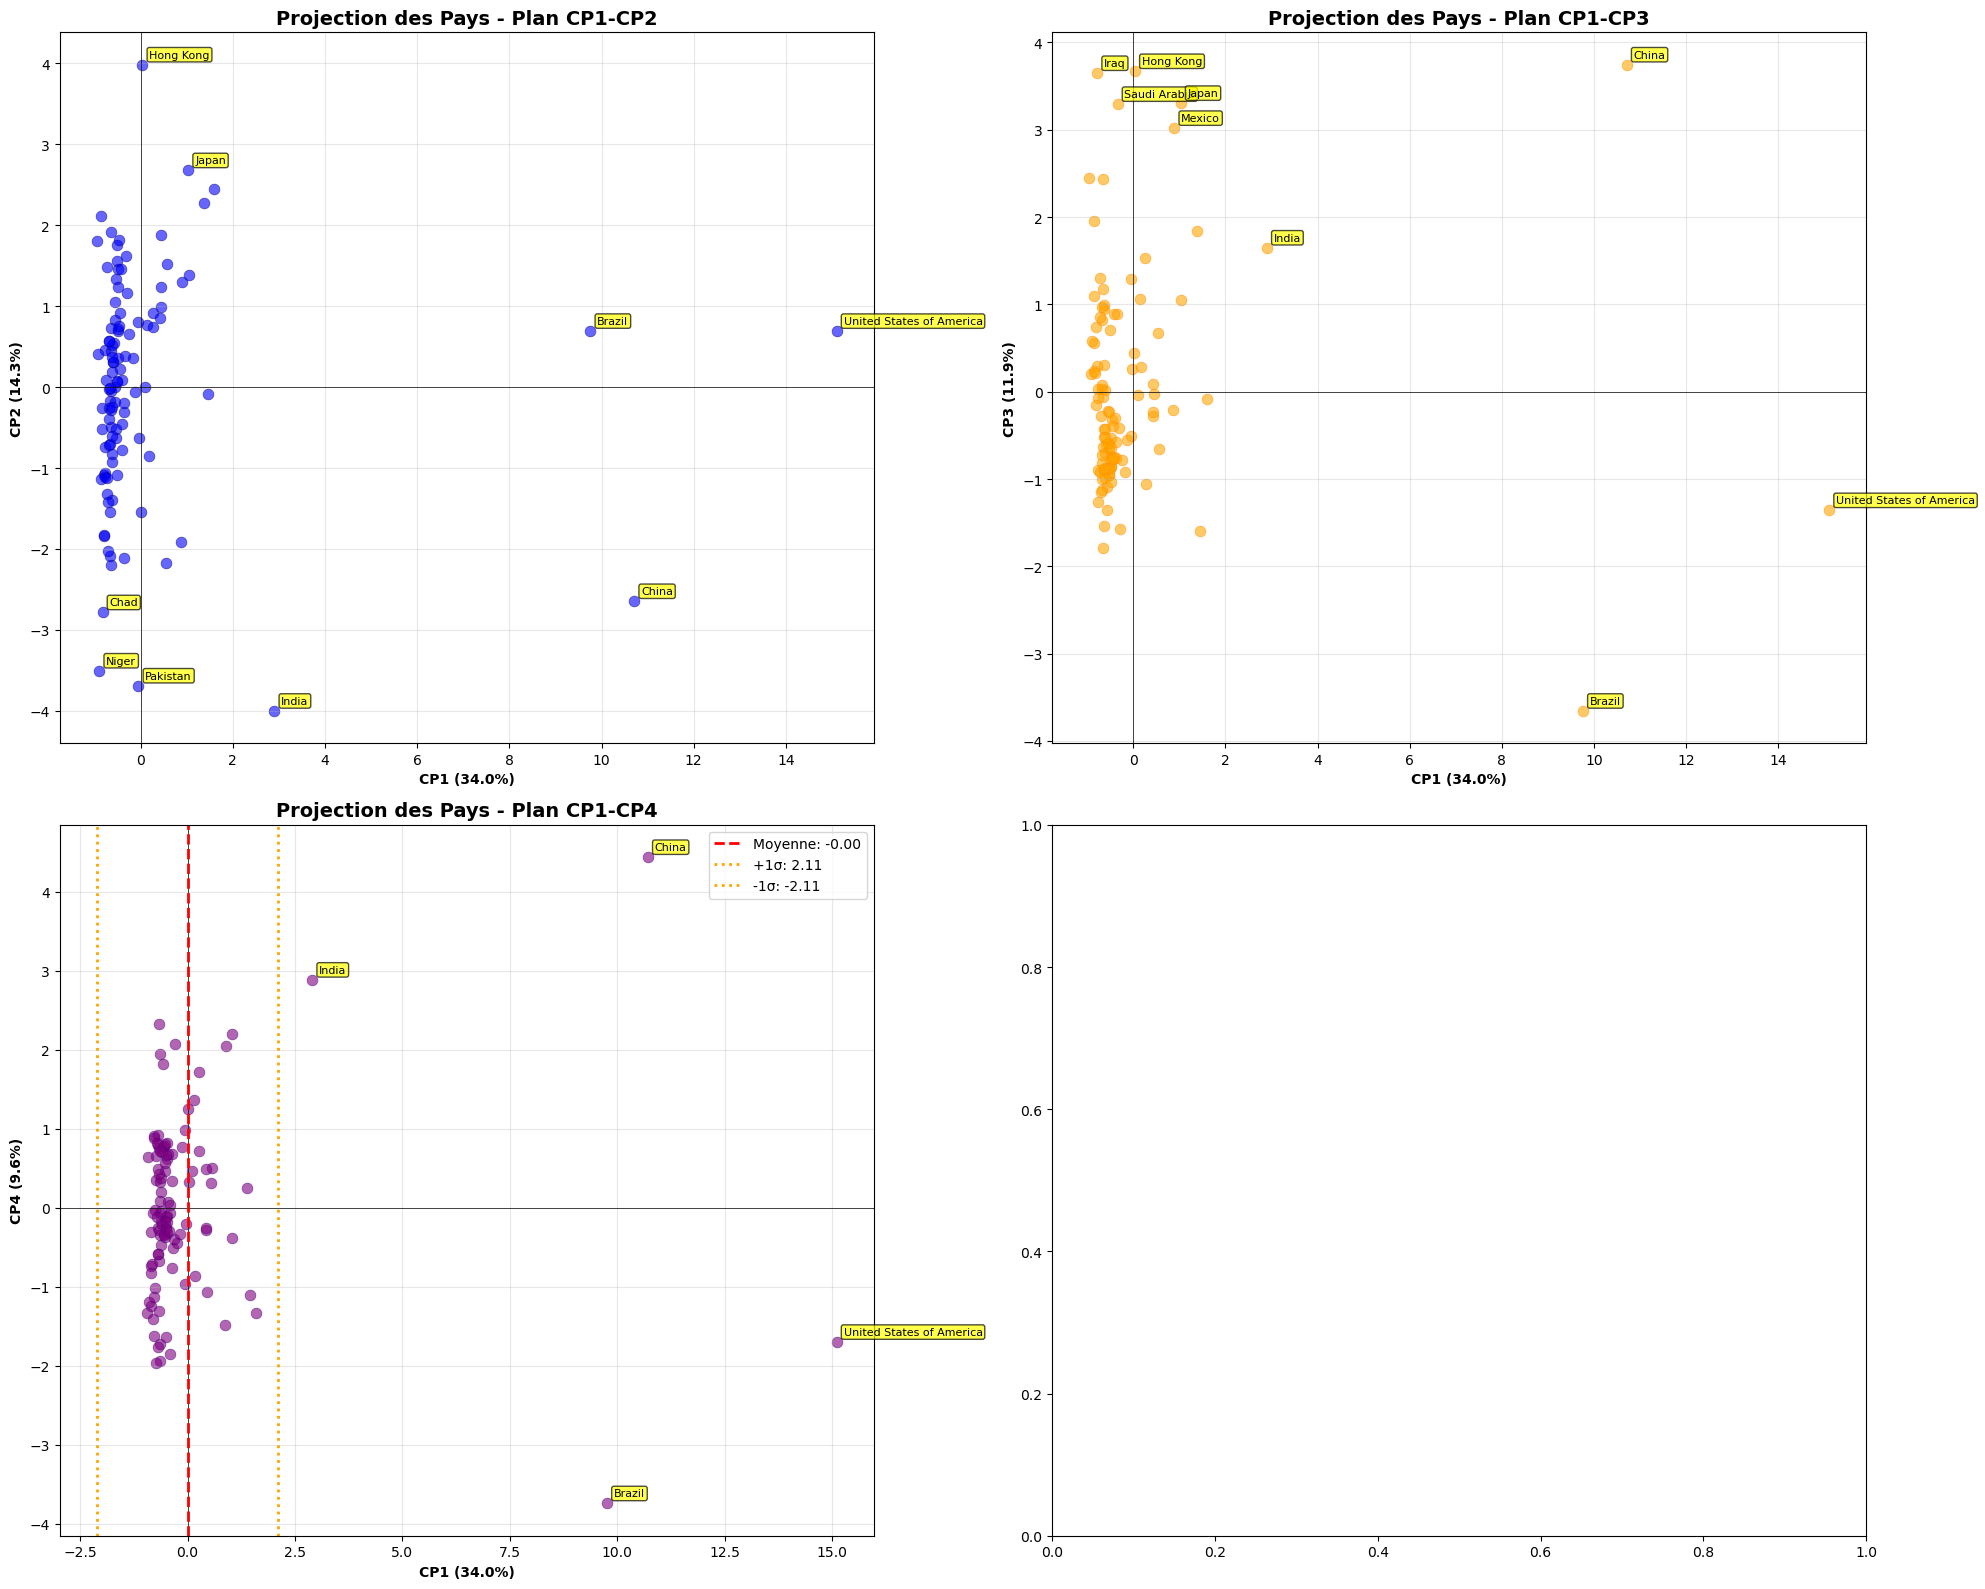


Pays avec des coordonnées extrêmes:
  CP1 élevé (+): Brazil, China, United States of America
  CP2 élevé (+): Hong Kong
  CP2 faible (-): India, Niger, Pakistan, Chad
  CP3 élevé (+): Saudi Arabia, Hong Kong, China, Iraq, Japan, Mexico
  CP3 faible (-): Brazil

✅ ANALYSE ACP TERMINÉE AVEC SUCCÈS
   📊 111 pays analysés avec données nettoyées
   📈 13 variables critiques utilisées
   🎯 4 composantes principales retenues
   📋 Variance totale expliquée: 69.8%
   🔧 Nettoyage automatique des données effectué

SAUVEGARDE DES RÉSULTATS:
   💾 Résultats ACP sauvegardés: resultats_acp_poule_qui_chante.csv
   💾 Dataset nettoyé sauvegardé: dataset_nettoye_poule_qui_chante.csv

🎯 PRÊT POUR LE CLUSTERING!
Les coordonnées ACP sont prêtes pour la classification des pays


In [49]:
print("\n8. PROJECTION DES INDIVIDUS (PAYS)")
print("-" * 50)

# Création du DataFrame avec les coordonnées des pays
df_pca_results = pd.DataFrame(X_pca[:, :n_comp_to_analyze], 
                            columns=[f'CP{i+1}' for i in range(n_comp_to_analyze)])
df_pca_results['pays'] = df_acp['pays'].values

print(f"Coordonnées des pays calculées sur {n_comp_to_analyze} composantes principales")

# Visualisation de la projection des pays
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

# Plan CP1-CP2
ax = axes[0, 0]
scatter = ax.scatter(df_pca_results['CP1'], df_pca_results['CP2'], 
                   alpha=0.6, s=60, c='blue', edgecolors='navy', linewidth=0.5)
ax.set_xlabel(f'CP1 ({variance_explained[0]*100:.1f}%)', fontweight='bold')
ax.set_ylabel(f'CP2 ({variance_explained[1]*100:.1f}%)', fontweight='bold')
ax.set_title('Projection des Pays - Plan CP1-CP2', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linewidth=0.5)
ax.axvline(x=0, color='k', linewidth=0.5)

# Annotation des pays extrêmes sur CP1-CP2
extreme_threshold = 2.5
for _, row in df_pca_results.iterrows():
   if abs(row['CP1']) > extreme_threshold or abs(row['CP2']) > extreme_threshold:
       ax.annotate(row['pays'], (row['CP1'], row['CP2']), 
                  xytext=(5, 5), textcoords='offset points', fontsize=8,
                  bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.7))

# Plan CP1-CP3
ax = axes[0, 1]
scatter = ax.scatter(df_pca_results['CP1'], df_pca_results['CP3'], 
                   alpha=0.6, s=60, c='orange', edgecolors='darkorange', linewidth=0.5)
ax.set_xlabel(f'CP1 ({variance_explained[0]*100:.1f}%)', fontweight='bold')
ax.set_ylabel(f'CP3 ({variance_explained[2]*100:.1f}%)', fontweight='bold')
ax.set_title('Projection des Pays - Plan CP1-CP3', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linewidth=0.5)
ax.axvline(x=0, color='k', linewidth=0.5)

# Annotation des pays extrêmes sur CP1-CP3
for _, row in df_pca_results.iterrows():
   if abs(row['CP1']) > extreme_threshold or abs(row['CP3']) > extreme_threshold:
       ax.annotate(row['pays'], (row['CP1'], row['CP3']), 
                  xytext=(5, 5), textcoords='offset points', fontsize=8,
                  bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.7))

# Plan CP1-CP4
ax = axes[1, 0]
scatter = ax.scatter(df_pca_results['CP1'], df_pca_results['CP4'], 
                  alpha=0.6, s=60, c='purple', edgecolors='indigo', linewidth=0.5)
ax.set_xlabel(f'CP1 ({variance_explained[0]*100:.1f}%)', fontweight='bold')
ax.set_ylabel(f'CP4 ({variance_explained[3]*100:.1f}%)', fontweight='bold')
ax.set_title('Projection des Pays - Plan CP1-CP4', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linewidth=0.5)
ax.axvline(x=0, color='k', linewidth=0.5)

# Annotation des pays extrêmes sur CP1-CP4
for _, row in df_pca_results.iterrows():
   if abs(row['CP1']) > extreme_threshold or abs(row['CP4']) > extreme_threshold:
       ax.annotate(row['pays'], (row['CP1'], row['CP4']), 
                  xytext=(5, 5), textcoords='offset points', fontsize=8,
                  bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.7))
# Plan CP1-CP5  
#ax = axes[1, 1]
#scatter = ax.scatter(df_pca_results['CP1'], df_pca_results['CP5'], 
 #                  alpha=0.6, s=60, c='green', edgecolors='darkgreen', linewidth=0.5)
#ax.set_xlabel(f'CP1 ({variance_explained[0]*100:.1f}%)', fontweight='bold')
#ax.set_ylabel(f'CP5 ({variance_explained[4]*100:.1f}%)', fontweight='bold')
#ax.set_title('Projection des Pays - Plan CP1-CP5', fontsize=14, fontweight='bold')
#ax.grid(True, alpha=0.3)
#ax.axhline(y=0, color='k', linewidth=0.5)
#ax.axvline(x=0, color='k', linewidth=0.5)

# Annotation des pays extrêmes sur CP1-CP5
#for _, row in df_pca_results.iterrows():
#   if abs(row['CP1']) > extreme_threshold or abs(row['CP5']) > extreme_threshold:
#       ax.annotate(row['pays'], (row['CP1'], row['CP5']), 
#                  xytext=(5, 5), textcoords='offset points', fontsize=8,
#                  bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.7))
# Plan CP2-CP3  
#ax = axes[1, 1]
#scatter = ax.scatter(df_pca_results['CP2'], df_pca_results['CP3'], 
#                   alpha=0.6, s=60, c='green', edgecolors='darkgreen', linewidth=0.5)
#ax.set_xlabel(f'CP2 ({variance_explained[1]*100:.1f}%)', fontweight='bold')
#ax.set_ylabel(f'CP3 ({variance_explained[2]*100:.1f}%)', fontweight='bold')
#ax.set_title('Projection des Pays - Plan CP2-CP3', fontsize=14, fontweight='bold')
#ax.grid(True, alpha=0.3)
#ax.axhline(y=0, color='k', linewidth=0.5)
#ax.axvline(x=0, color='k', linewidth=0.5)

# Annotation des pays extrêmes sur CP2-CP3
#for _, row in df_pca_results.iterrows():
#   if abs(row['CP2']) > extreme_threshold or abs(row['CP3']) > extreme_threshold:
#       ax.annotate(row['pays'], (row['CP2'], row['CP3']), 
#                  xytext=(5, 5), textcoords='offset points', fontsize=8,
#                  bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.7))



# Ajout de statistiques sur la distribution
mean_cp1 = df_pca_results['CP1'].mean()
std_cp1 = df_pca_results['CP1'].std()
ax.axvline(mean_cp1, color='red', linestyle='--', linewidth=2, label=f'Moyenne: {mean_cp1:.2f}')
ax.axvline(mean_cp1 + std_cp1, color='orange', linestyle=':', linewidth=2, label=f'+1σ: {mean_cp1+std_cp1:.2f}')
ax.axvline(mean_cp1 - std_cp1, color='orange', linestyle=':', linewidth=2, label=f'-1σ: {mean_cp1-std_cp1:.2f}')
ax.legend()


plt.tight_layout()
plt.show()

# Identification des pays extrêmes sur chaque composante
print("\nPays avec des coordonnées extrêmes:")
for i in range(min(3, n_comp_to_analyze)):
   cp_col = f'CP{i+1}'
   
   # Pays avec valeurs extrêmes (> 2 écarts-types)
   mean_cp = df_pca_results[cp_col].mean()
   std_cp = df_pca_results[cp_col].std()
   
   extreme_positive = df_pca_results[df_pca_results[cp_col] > mean_cp + 2*std_cp]
   extreme_negative = df_pca_results[df_pca_results[cp_col] < mean_cp - 2*std_cp]
   
   if len(extreme_positive) > 0:
       print(f"  {cp_col} élevé (+): {', '.join(extreme_positive['pays'].tolist())}")
   if len(extreme_negative) > 0:
       print(f"  {cp_col} faible (-): {', '.join(extreme_negative['pays'].tolist())}")

print("\n✅ ANALYSE ACP TERMINÉE AVEC SUCCÈS")
print(f"   📊 {len(df_acp)} pays analysés avec données nettoyées")
print(f"   📈 {len(variables_acp)} variables critiques utilisées")
print(f"   🎯 {n_comp_to_analyze} composantes principales retenues")
print(f"   📋 Variance totale expliquée: {variance_cumulative[n_comp_to_analyze-1]*100:.1f}%")
print(f"   🔧 Nettoyage automatique des données effectué")

# Sauvegarde des résultats ACP pour le clustering
print(f"\nSAUVEGARDE DES RÉSULTATS:")
try:
   df_pca_results.to_csv('resultats_acp_poule_qui_chante.csv', index=False)
   print(f"   💾 Résultats ACP sauvegardés: resultats_acp_poule_qui_chante.csv")
   
   # Sauvegarde également des données nettoyées pour référence
   df_acp.to_csv('dataset_nettoye_poule_qui_chante.csv', index=False)
   print(f"   💾 Dataset nettoyé sauvegardé: dataset_nettoye_poule_qui_chante.csv")
   
except Exception as e:
   print(f"   ⚠️  Erreur de sauvegarde: {e}")
   print(f"   Les résultats restent disponibles en mémoire")

print("\n" + "="*70)
print("🎯 PRÊT POUR LE CLUSTERING!")
print("Les coordonnées ACP sont prêtes pour la classification des pays")
print("="*70)

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 8.5 - CHARGEMENT DES RÉSULTATS ACP</h2>
</div>

In [50]:
print("\n8. CHARGEMENT DES DONNÉES ACP")
print("-" * 50)

try:
    # Chargement des résultats ACP
    df_pca = pd.read_csv('resultats_acp_poule_qui_chante.csv')
    print(f"✅ Résultats ACP chargés: {df_pca.shape[0]} pays, {df_pca.shape[1]-1} composantes")
    
    # Chargement du dataset original pour l'analyse finale
    df_original = pd.read_csv('dataset_final_poule_qui_chante.csv')
    print(f"✅ Dataset original chargé: {df_original.shape}")
    
except FileNotFoundError:
    print("❌ Fichiers ACP non trouvés - lancez d'abord l'analyse ACP")
    exit()

# Identification des composantes disponibles
cp_columns = [col for col in df_pca.columns if col.startswith('CP')]
print(f"Composantes principales disponibles: {cp_columns}")

# Préparation des données pour le clustering
X_clustering = df_pca[cp_columns].values
print(f"Matrice de clustering: {X_clustering.shape[0]} pays × {X_clustering.shape[1]} composantes")


8. CHARGEMENT DES DONNÉES ACP
--------------------------------------------------
✅ Résultats ACP chargés: 111 pays, 4 composantes
✅ Dataset original chargé: (111, 14)
Composantes principales disponibles: ['CP1', 'CP2', 'CP3', 'CP4']
Matrice de clustering: 111 pays × 4 composantes


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 9 - CLASSIFICATION ASCENDANTE HIÉRARCHIQUE (CAH)</h2>
</div>


9. CLASSIFICATION ASCENDANTE HIÉRARCHIQUE (CAH)
--------------------------------------------------
Calcul de la matrice des distances (euclidienne)...


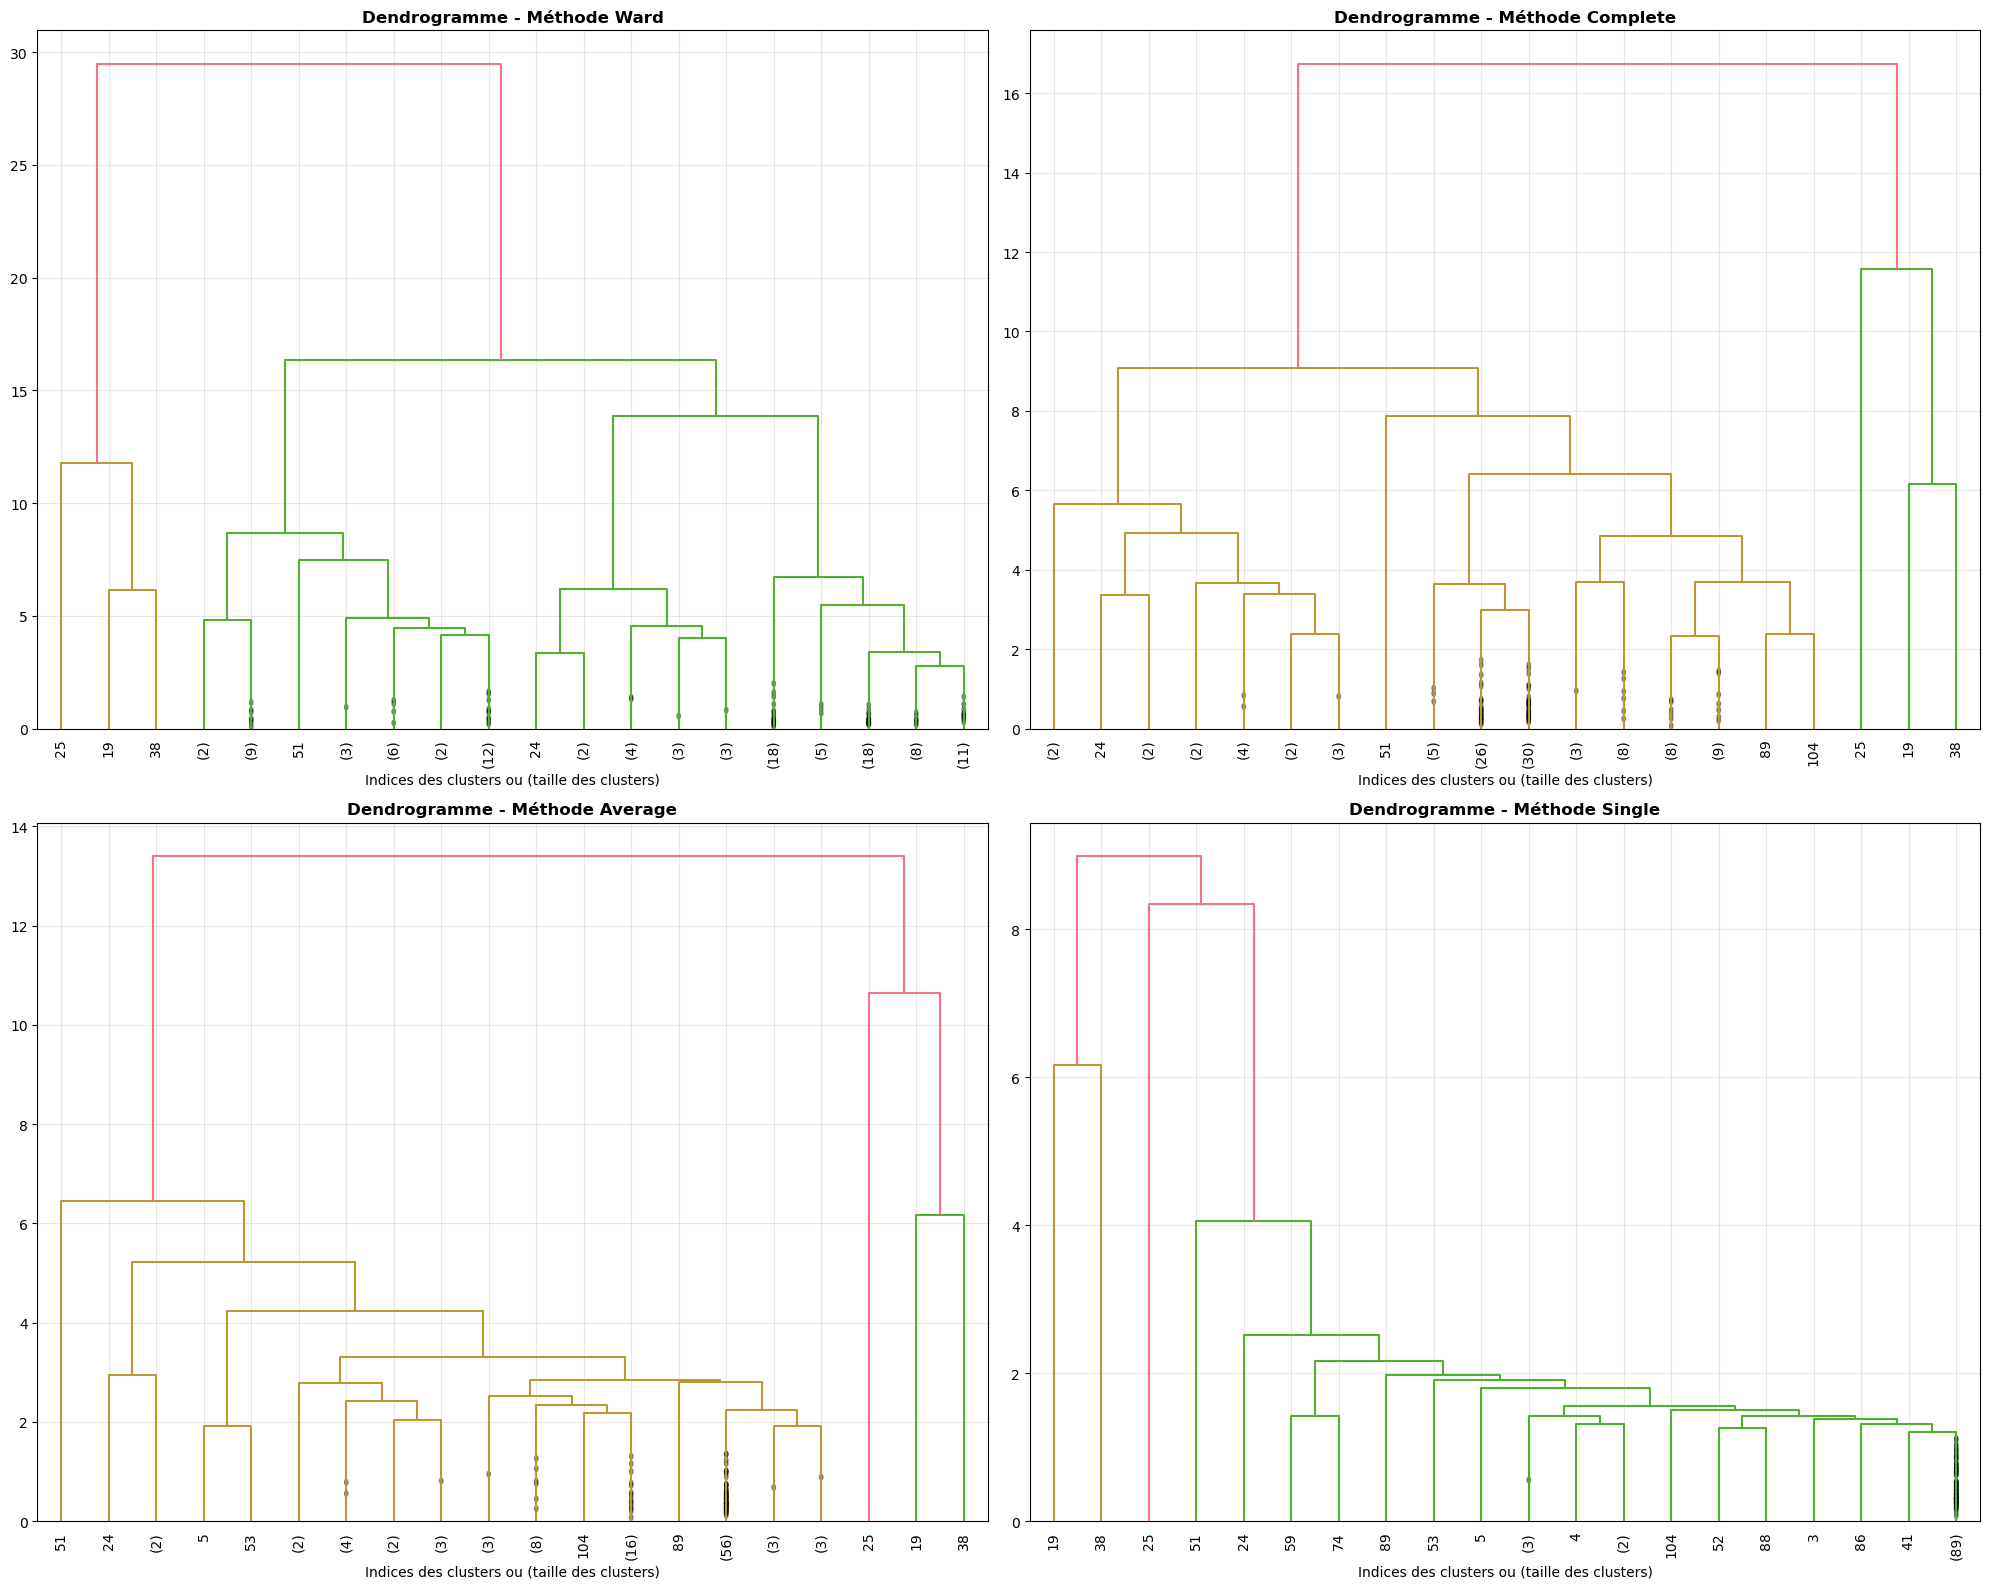

Analyse avec la méthode Ward:


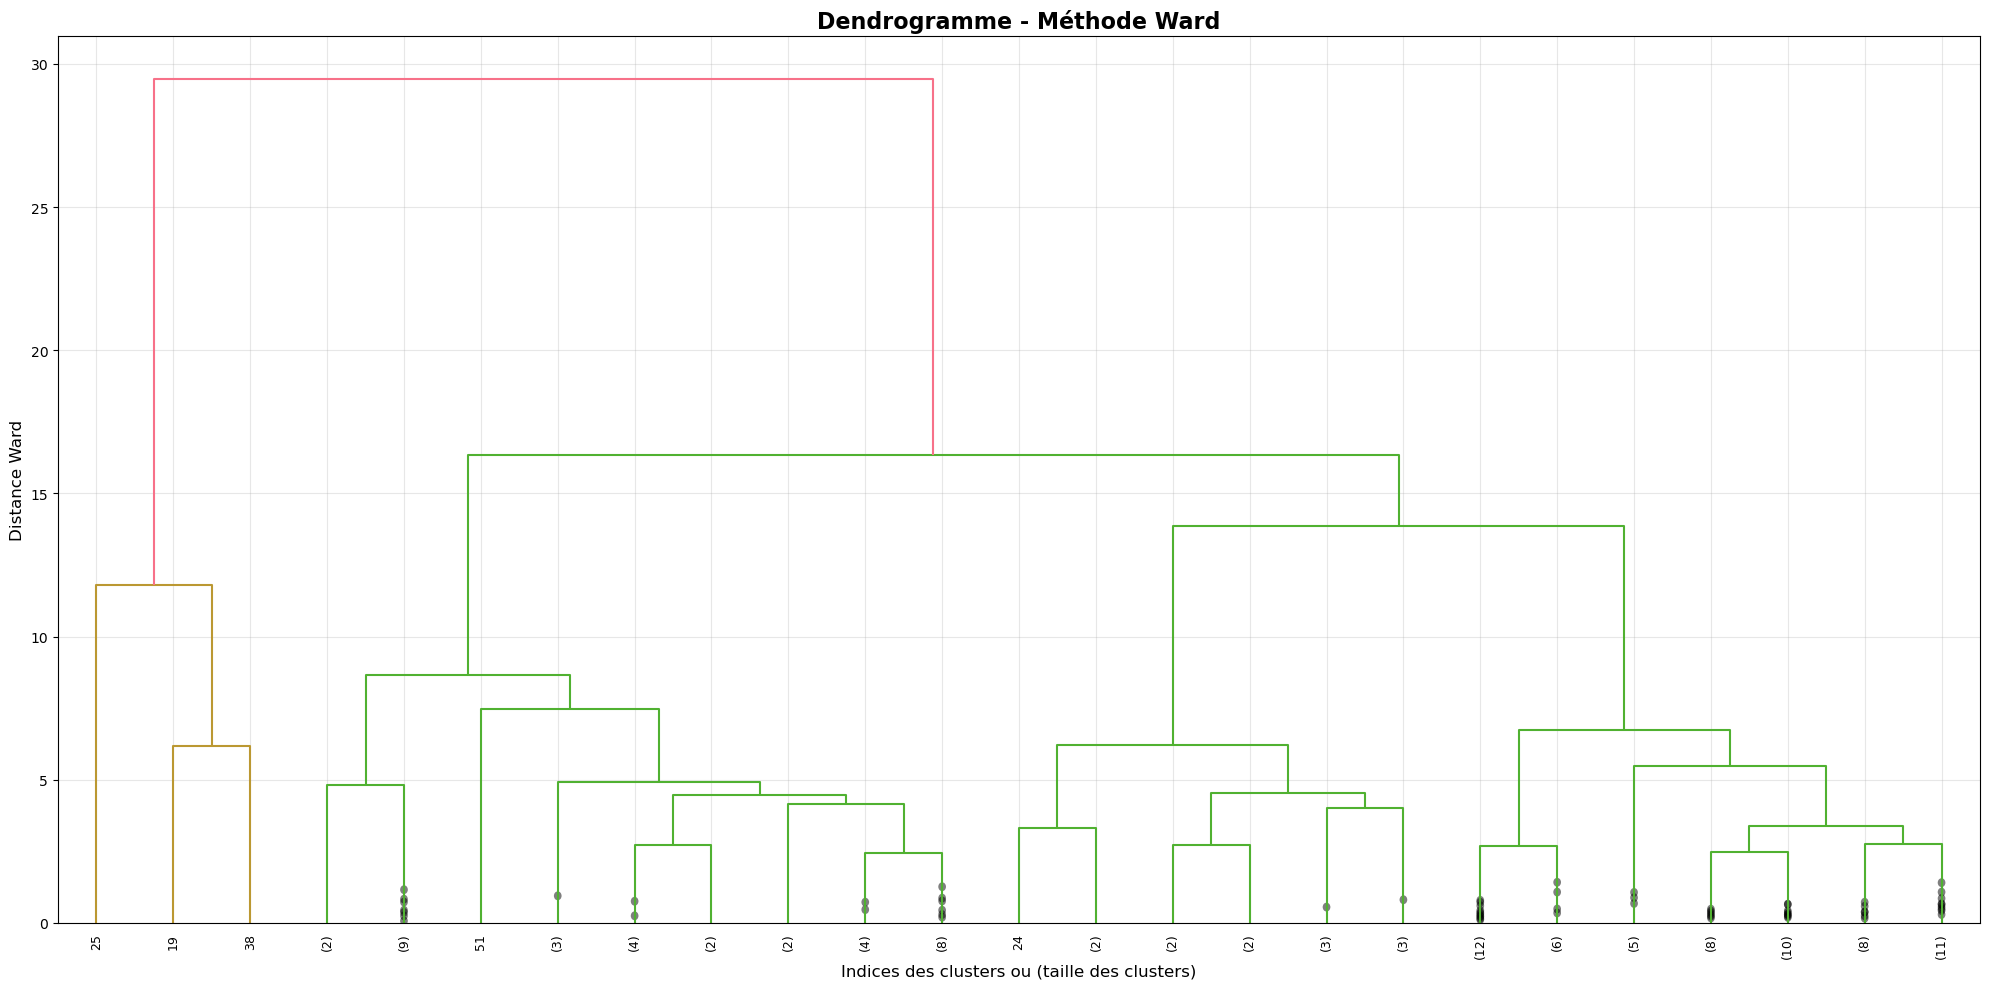

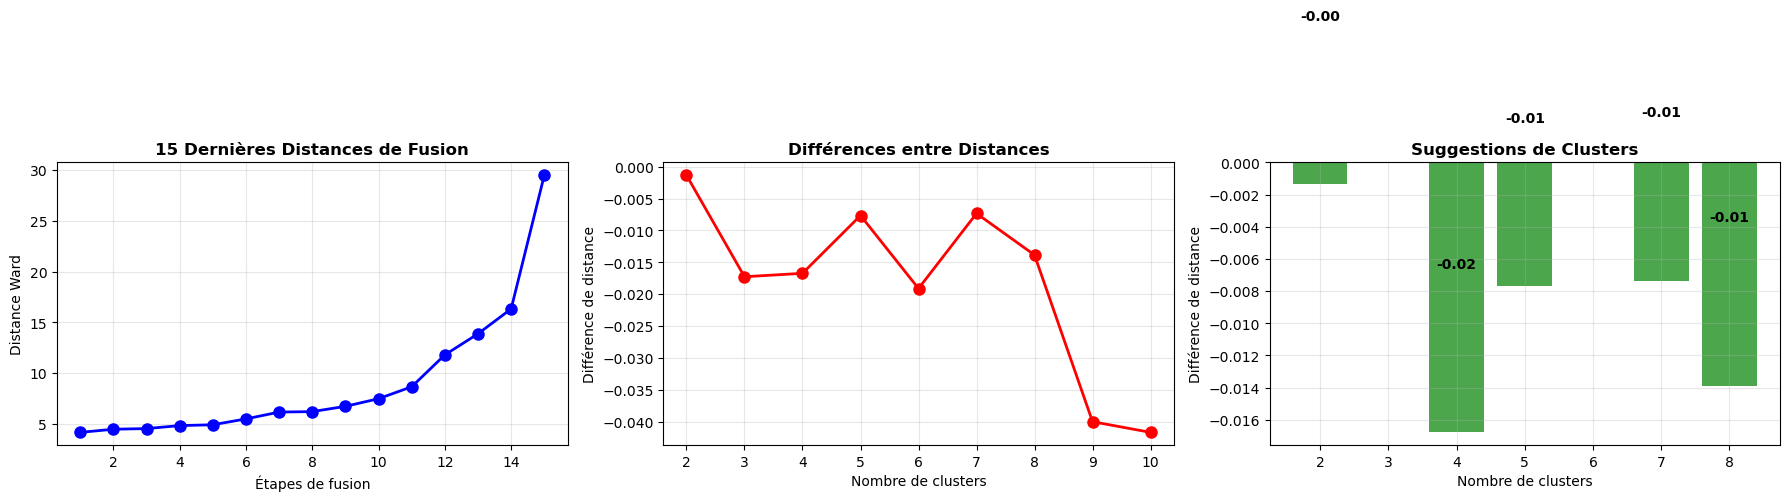

Nombre optimal suggéré par CAH: 5


In [51]:
print("\n9. CLASSIFICATION ASCENDANTE HIÉRARCHIQUE (CAH)")
print("-" * 50)

# Calcul de la matrice des distances
print("Calcul de la matrice des distances (euclidienne)...")
distances = pdist(X_clustering, metric='euclidean')

# Test de différentes méthodes de liaison
linkage_methods = ['ward', 'complete', 'average', 'single']
linkage_results = {}

for method in linkage_methods:
    linkage_results[method] = linkage(distances, method=method)

# Visualisation des dendrogrammes
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
axes = axes.ravel()

for i, method in enumerate(linkage_methods):
    ax = axes[i]
    Z = linkage_results[method]
    
    dendrogram(Z, ax=ax, truncate_mode='lastp', p=20, 
               leaf_rotation=90, leaf_font_size=10,
               show_contracted=True, color_threshold=0.7*max(Z[:,2]))
    
    ax.set_title(f'Dendrogramme - Méthode {method.capitalize()}', 
                fontsize=12, fontweight='bold')
    ax.set_xlabel('Indices des clusters ou (taille des clusters)')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Focus sur la méthode Ward
print("Analyse avec la méthode Ward:")
Z_ward = linkage_results['ward']

# Dendrogramme détaillé Ward
plt.figure(figsize=(20, 10))
dendrogram(Z_ward, truncate_mode='lastp', p=25,
           leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, 
           color_threshold=0.7*max(Z_ward[:,2]))
plt.title('Dendrogramme - Méthode Ward', fontsize=16, fontweight='bold')
plt.xlabel('Indices des clusters ou (taille des clusters)', fontsize=12)
plt.ylabel('Distance Ward', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Analyse du coude pour nombre optimal de clusters
distances_fusion = Z_ward[:, 2]
differences = np.diff(distances_fusion[::-1])

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.plot(range(1, 16), distances_fusion[-15:], 'bo-', linewidth=2, markersize=8)
plt.title('15 Dernières Distances de Fusion', fontweight='bold')
plt.xlabel('Étapes de fusion')
plt.ylabel('Distance Ward')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(range(2, 11), differences[-9:], 'ro-', linewidth=2, markersize=8)
plt.title('Différences entre Distances', fontweight='bold')
plt.xlabel('Nombre de clusters')
plt.ylabel('Différence de distance')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
top_differences_idx = np.argsort(differences[-9:])[-5:] + 2
top_differences_val = differences[-9:][top_differences_idx-2]
bars = plt.bar(top_differences_idx, top_differences_val, alpha=0.7, color='green')
plt.title('Suggestions de Clusters', fontweight='bold')
plt.xlabel('Nombre de clusters')
plt.ylabel('Différence de distance')
plt.grid(True, alpha=0.3)

for bar, val in zip(bars, top_differences_val):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.2f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

optimal_k_cah = np.argmax(differences[-7:]) + 2
print(f"Nombre optimal suggéré par CAH: {optimal_k_cah}")


10. CLUSTERING K-MEANS
--------------------------------------------------
Test de différents nombres de clusters...


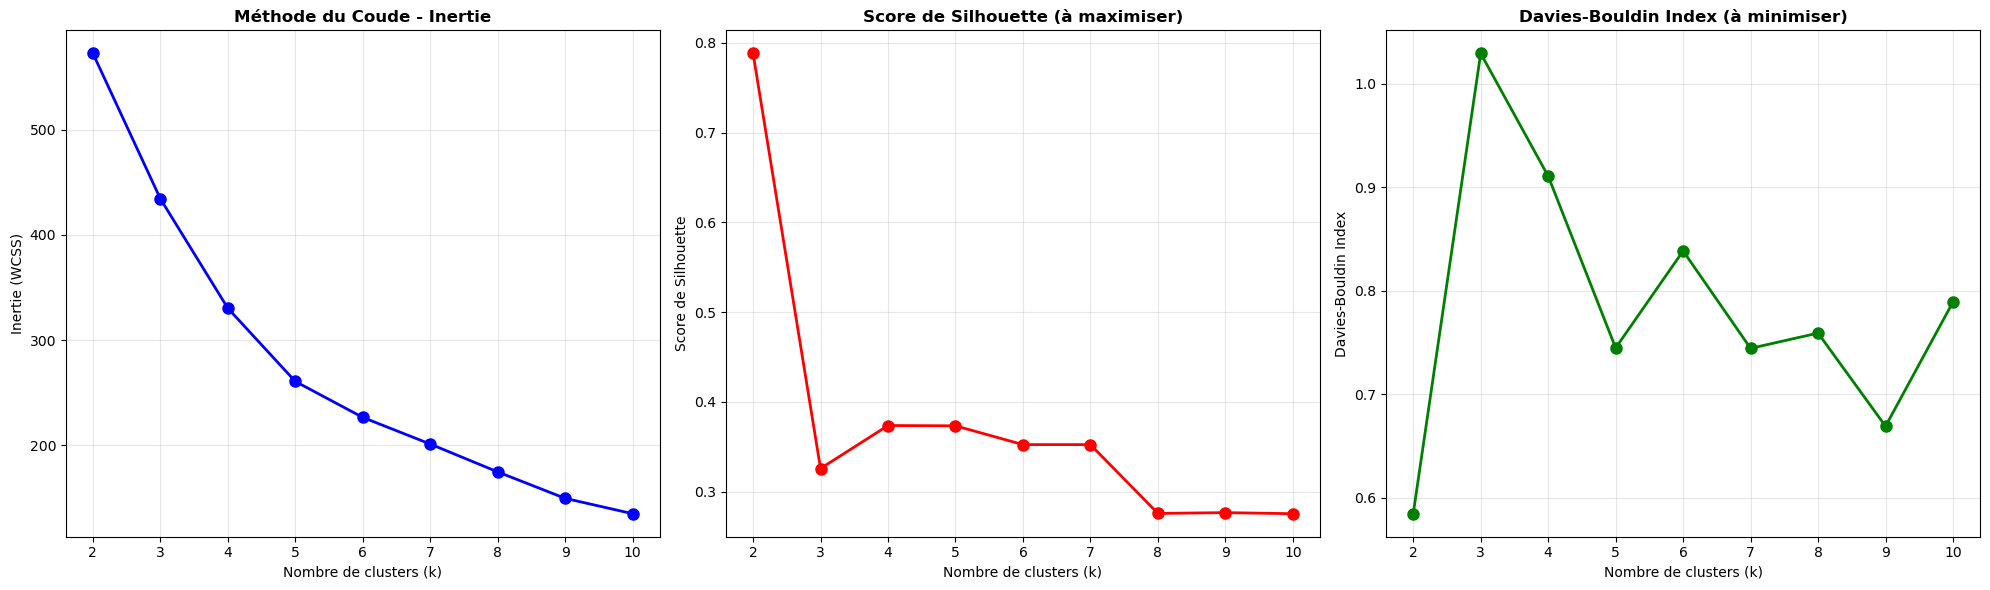


Suggestions pour k optimal:
  Score de Silhouette maximal: k = 2
  Davies-Bouldin minimal: k = 2
  CAH suggérait: k = 5

K final retenu: 5


In [52]:
print("\n10. CLUSTERING K-MEANS")
print("-" * 50)

# Détermination du nombre optimal de clusters
# Basé sur l'analyse CAH précédente, on teste plusieurs valeurs
k_range = range(2, 11)
inertias = []
silhouette_scores = []
davies_bouldin_scores = []

print("Test de différents nombres de clusters...")
for k in k_range:
    # Application du K-means
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_clustering)
    
    # Calcul des métriques : 
    inertias.append(kmeans.inertia_) #Somme des distances au carré entre chaque point et le centre de son cluster-Plus faible = clusters plus compacts-Diminue toujours quand k augmente
    silhouette_scores.append(silhouette_score(X_clustering, cluster_labels)) #Mesure la cohésion interne vs séparation externe des clusters-Valeurs de -1 à +1, optimal proche de 1-Formule : (b-a)/max(a,b) où a=distance moyenne intra-cluster, b=distance moyenne au cluster le plus proche
    davies_bouldin_scores.append(davies_bouldin_score(X_clustering, cluster_labels)) #Rapport entre dispersion intra-cluster et séparation inter-clusters-Plus proche de 0 = meilleur clustering-Pénalise les clusters étendus et rapprochés
    

# Visualisation des métriques pour choisir k optimal
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Méthode du coude (inertie)
ax = axes[0]
ax.plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
ax.set_xlabel('Nombre de clusters (k)')
ax.set_ylabel('Inertie (WCSS)')
ax.set_title('Méthode du Coude - Inertie', fontweight='bold')
ax.grid(True, alpha=0.3)

# Score de silhouette (à maximiser)
ax = axes[1]
ax.plot(k_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
ax.set_xlabel('Nombre de clusters (k)')
ax.set_ylabel('Score de Silhouette')
ax.set_title('Score de Silhouette (à maximiser)', fontweight='bold')
ax.grid(True, alpha=0.3)

# Davies-Bouldin (à minimiser)
ax = axes[2]
ax.plot(k_range, davies_bouldin_scores, 'go-', linewidth=2, markersize=8)
ax.set_xlabel('Nombre de clusters (k)')
ax.set_ylabel('Davies-Bouldin Index')
ax.set_title('Davies-Bouldin Index (à minimiser)', fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Suggestion automatique du k optimal
optimal_k_silhouette = k_range[np.argmax(silhouette_scores)]
optimal_k_davies = k_range[np.argmin(davies_bouldin_scores)]

print(f"\nSuggestions pour k optimal:")
print(f"  Score de Silhouette maximal: k = {optimal_k_silhouette}")
print(f"  Davies-Bouldin minimal: k = {optimal_k_davies}")
print(f"  CAH suggérait: k = {optimal_k_cah if 'optimal_k_cah' in locals() else 'non défini'}")

# Choix du k final (on prend la valeur suggérée par CAH ou silhouette)
k_final = optimal_k_cah if 'optimal_k_cah' in locals() else optimal_k_silhouette
print(f"\nK final retenu: {k_final}")



In [53]:
# ============================================================================
# Application du K-means final
# ============================================================================

print(f"\nApplication du K-means avec k = {k_final}...")
kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
clusters_kmeans = kmeans_final.fit_predict(X_clustering)

# Ajout des clusters au DataFrame des résultats
df_clustering_results = df_pca_results.copy()
df_clustering_results['cluster_kmeans'] = clusters_kmeans

print(f"✅ K-means terminé avec {k_final} clusters")
print(f"   Inertie finale: {kmeans_final.inertia_:.2f}")
print(f"   Silhouette score: {silhouette_score(X_clustering, clusters_kmeans):.3f}")

# Analyse de la composition des clusters
print(f"\nComposition des clusters K-means:")
for i in range(k_final):
    cluster_countries = df_clustering_results[df_clustering_results['cluster_kmeans'] == i]['pays'].tolist()
    print(f"  Cluster {i} ({len(cluster_countries)} pays): {', '.join(cluster_countries[:8])}{'...' if len(cluster_countries) > 8 else ''}")




Application du K-means avec k = 5...
✅ K-means terminé avec 5 clusters
   Inertie finale: 260.65
   Silhouette score: 0.373

Composition des clusters K-means:
  Cluster 0 (60 pays): Argentina, Armenia, Australia, Austria, Barbados, Belarus, Belize, Bolivia...
  Cluster 1 (2 pays): Brazil, United States of America
  Cluster 2 (1 pays): China
  Cluster 3 (33 pays): Albania, Algeria, Azerbaijan, Benin, Bosnia and Herzegovina, Cameroon, Cote d'Ivoire, Georgia...
  Cluster 4 (15 pays): South Africa, Germany, Angola, Saudi Arabia, Belgium, Hong Kong, United Arab Emirates, France...



Visualisation des clusters K-means...


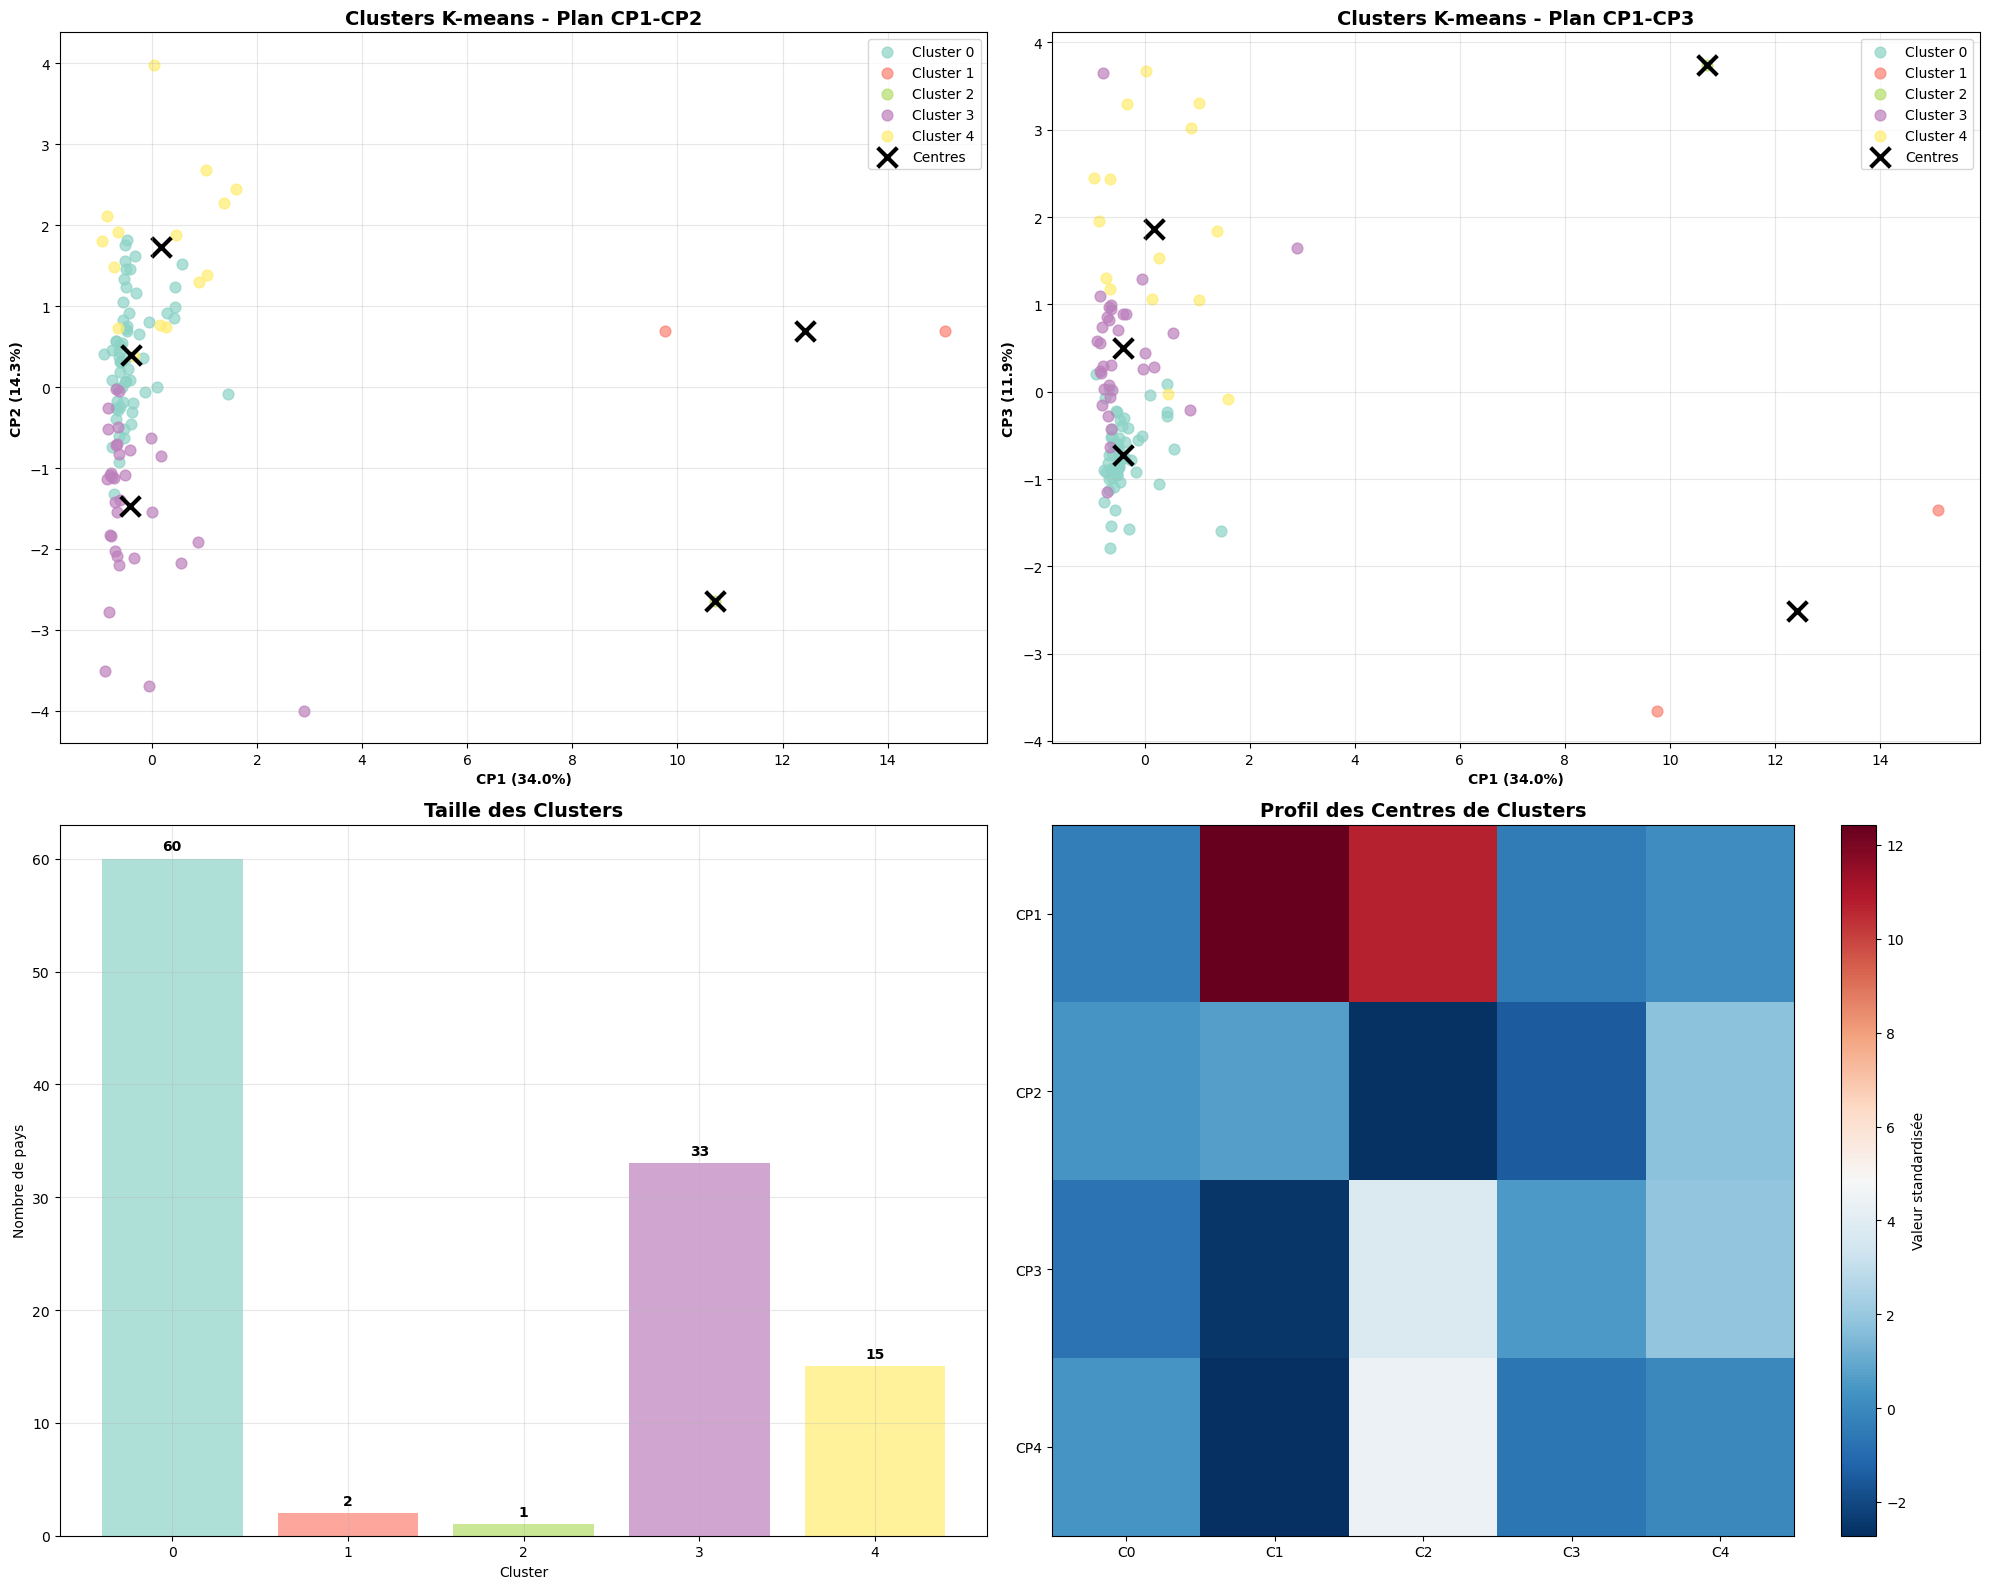

In [54]:
# ============================================================================
# Visualisation des clusters K-means
# ============================================================================

print("\nVisualisation des clusters K-means...")

# Palette de couleurs pour les clusters
colors = plt.cm.Set3(np.linspace(0, 1, k_final))

fig, axes = plt.subplots(2, 2, figsize=(20, 16))

# Plan CP1-CP2 avec clusters
ax = axes[0, 0]
for i in range(k_final):
    cluster_data = df_clustering_results[df_clustering_results['cluster_kmeans'] == i]
    ax.scatter(cluster_data['CP1'], cluster_data['CP2'], 
              c=[colors[i]], label=f'Cluster {i}', alpha=0.7, s=60)

# Centres des clusters
centers_2d = kmeans_final.cluster_centers_[:, [0, 1]]  # CP1 et CP2
ax.scatter(centers_2d[:, 0], centers_2d[:, 1], 
          c='black', marker='x', s=200, linewidths=3, label='Centres')

ax.set_xlabel(f'CP1 ({variance_explained[0]*100:.1f}%)', fontweight='bold')
ax.set_ylabel(f'CP2 ({variance_explained[1]*100:.1f}%)', fontweight='bold')
ax.set_title('Clusters K-means - Plan CP1-CP2', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plan CP1-CP3 avec clusters
ax = axes[0, 1]
for i in range(k_final):
    cluster_data = df_clustering_results[df_clustering_results['cluster_kmeans'] == i]
    ax.scatter(cluster_data['CP1'], cluster_data['CP3'], 
              c=[colors[i]], label=f'Cluster {i}', alpha=0.7, s=60)

centers_2d = kmeans_final.cluster_centers_[:, [0, 2]]  # CP1 et CP3
ax.scatter(centers_2d[:, 0], centers_2d[:, 1], 
          c='black', marker='x', s=200, linewidths=3, label='Centres')

ax.set_xlabel(f'CP1 ({variance_explained[0]*100:.1f}%)', fontweight='bold')
ax.set_ylabel(f'CP3 ({variance_explained[2]*100:.1f}%)', fontweight='bold')
ax.set_title('Clusters K-means - Plan CP1-CP3', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Distribution des tailles de clusters
ax = axes[1, 0]
cluster_sizes = df_clustering_results['cluster_kmeans'].value_counts().sort_index()
bars = ax.bar(range(k_final), cluster_sizes.values, alpha=0.7, color=colors)
ax.set_xlabel('Cluster')
ax.set_ylabel('Nombre de pays')
ax.set_title('Taille des Clusters', fontsize=14, fontweight='bold')
ax.set_xticks(range(k_final))
ax.grid(True, alpha=0.3)

# Ajout des valeurs sur les barres
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.5,
            f'{int(height)}', ha='center', va='bottom', fontweight='bold')

# Heatmap des centres de clusters
ax = axes[1, 1]
centers_scaled = kmeans_final.cluster_centers_
im = ax.imshow(centers_scaled.T, cmap='RdBu_r', aspect='auto')
ax.set_xticks(range(k_final))
ax.set_xticklabels([f'C{i}' for i in range(k_final)])
ax.set_yticks(range(len(variables_acp[:4])))  # Premières 4 composantes
ax.set_yticklabels([f'CP{i+1}' for i in range(4)])
ax.set_title('Profil des Centres de Clusters', fontsize=14, fontweight='bold')

# Colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Valeur standardisée')

plt.tight_layout()
plt.show()


11. COMPARAISON CAH vs K-MEANS
--------------------------------------------------
Accord entre CAH et K-means:
  Adjusted Rand Index: 0.847
  Normalized Mutual Information: 0.806

Tableau croisé CAH vs K-means:
K-means   0  1  2   3   4
CAH                      
0         2  0  0  31   2
1        58  0  0   2   0
2         0  2  0   0   0
3         0  0  0   0  13
4         0  0  1   0   0


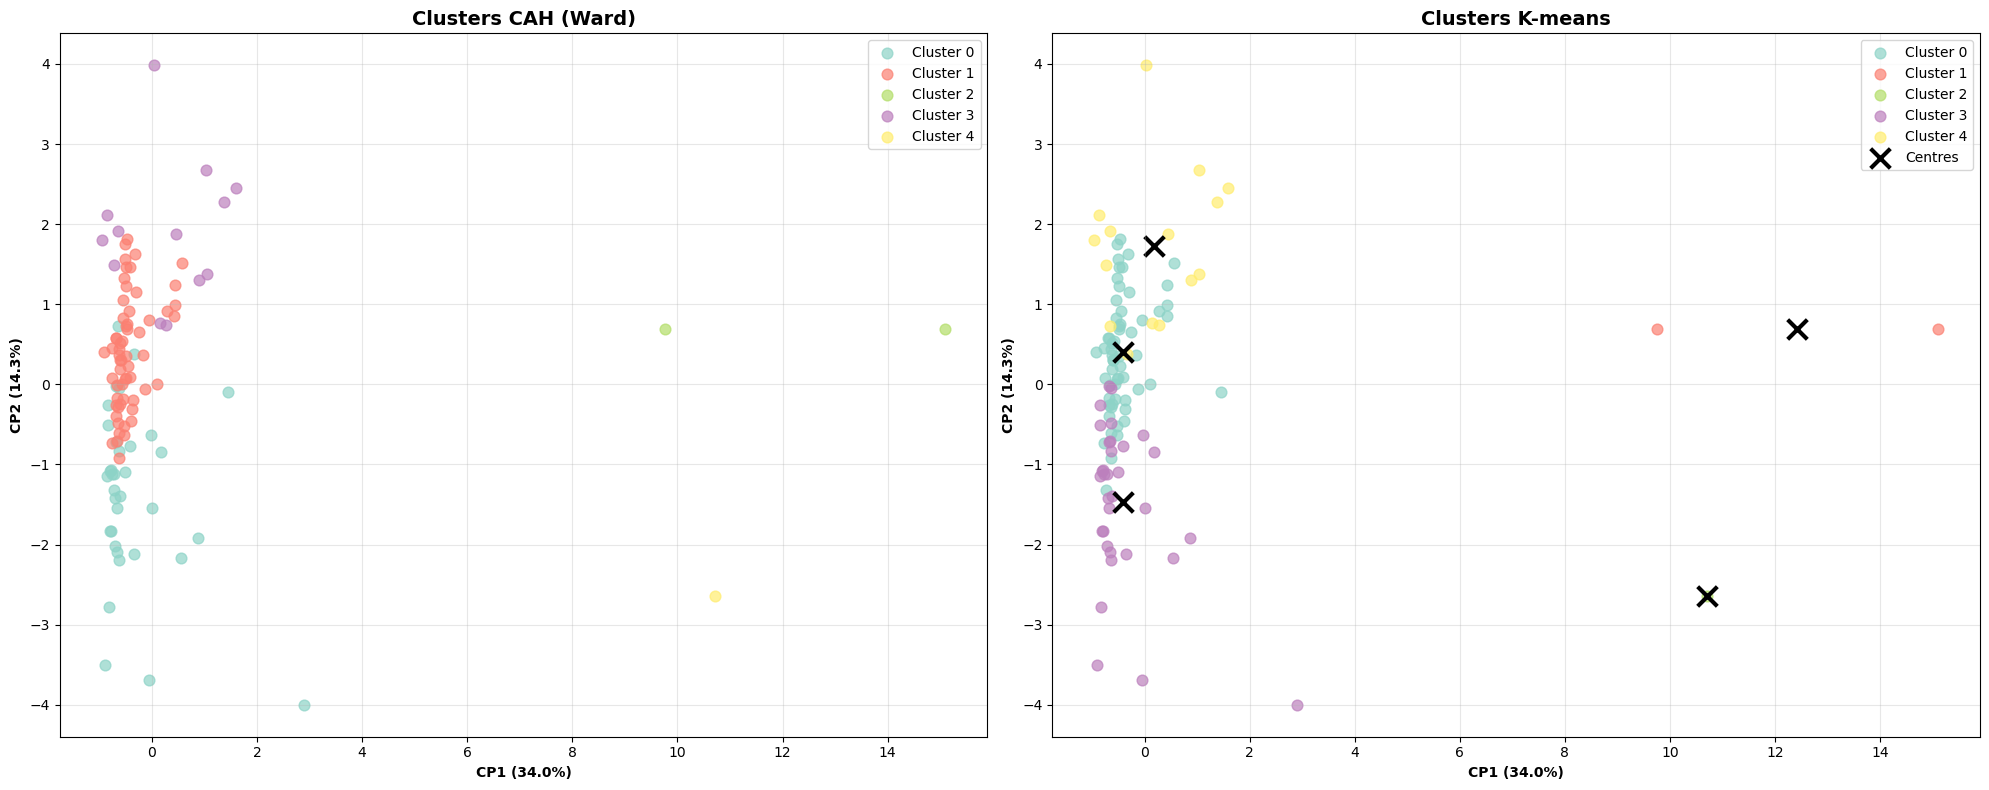

In [55]:
# ============================================================================
# Comparaison CAH vs K-means
# ============================================================================

print("\n11. COMPARAISON CAH vs K-MEANS")
print("-" * 50)

# Application de la CAH avec le même nombre de clusters
from sklearn.cluster import AgglomerativeClustering

cah_clustering = AgglomerativeClustering(n_clusters=k_final, linkage='ward')
clusters_cah = cah_clustering.fit_predict(X_clustering)

df_clustering_results['cluster_cah'] = clusters_cah

# Matrice de confusion entre les deux méthodes
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari_score = adjusted_rand_score(clusters_cah, clusters_kmeans)
nmi_score = normalized_mutual_info_score(clusters_cah, clusters_kmeans)

print(f"Accord entre CAH et K-means:")
print(f"  Adjusted Rand Index: {ari_score:.3f}")
print(f"  Normalized Mutual Information: {nmi_score:.3f}")

# Tableau croisé
crosstab = pd.crosstab(clusters_cah, clusters_kmeans, 
                      rownames=['CAH'], colnames=['K-means'])
print(f"\nTableau croisé CAH vs K-means:")
print(crosstab)

# Visualisation comparative
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# CAH
ax = axes[0]
for i in range(k_final):
    cluster_data = df_clustering_results[df_clustering_results['cluster_cah'] == i]
    ax.scatter(cluster_data['CP1'], cluster_data['CP2'], 
              c=[colors[i]], label=f'Cluster {i}', alpha=0.7, s=60)
ax.set_xlabel(f'CP1 ({variance_explained[0]*100:.1f}%)', fontweight='bold')
ax.set_ylabel(f'CP2 ({variance_explained[1]*100:.1f}%)', fontweight='bold')
ax.set_title('Clusters CAH (Ward)', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# K-means
ax = axes[1]
for i in range(k_final):
    cluster_data = df_clustering_results[df_clustering_results['cluster_kmeans'] == i]
    ax.scatter(cluster_data['CP1'], cluster_data['CP2'], 
              c=[colors[i]], label=f'Cluster {i}', alpha=0.7, s=60)
    
centers_2d = kmeans_final.cluster_centers_[:, [0, 1]]
ax.scatter(centers_2d[:, 0], centers_2d[:, 1], 
          c='black', marker='x', s=200, linewidths=3, label='Centres')

ax.set_xlabel(f'CP1 ({variance_explained[0]*100:.1f}%)', fontweight='bold')
ax.set_ylabel(f'CP2 ({variance_explained[1]*100:.1f}%)', fontweight='bold')
ax.set_title('Clusters K-means', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
# Visualisation géographique des clusters #1
fig = px.choropleth(df_clustering_results,
                  locations='pays',
                  locationmode='country names',
                  color='cluster_kmeans',
                  color_discrete_sequence=px.colors.qualitative.Set3,
                  title='Répartition Géographique des Clusters - Expansion La Poule qui Chante')

fig.update_layout(width=1200, height=700)
fig.show()

In [ ]:
# Préparation des données pour la carte #2
df_map = df_clustering_results.copy()
df_map['cluster_label'] = df_map['cluster_kmeans'].apply(lambda x: f'Cluster {x}')

# Carte avec style amélioré
fig = px.choropleth(df_map,
                  locations='pays',
                  locationmode='country names',
                  color='cluster_label',
                  color_discrete_sequence=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FECA57', '#FF9FF3', '#54A0FF'],
                  title='Cartographie des Clusters de Pays - Opportunités d\'Expansion Internationale')

fig.update_layout(
   geo=dict(
       showframe=False,
       showcoastlines=True,
       projection_type='natural earth'
   ),
   font=dict(size=14),
   width=1400,
   height=800,
   margin=dict(l=0, r=0, t=50, b=0)
)

fig.update_traces(marker_line_width=0.5, marker_line_color="white")
fig.show()

In [58]:
# Sauvegarde des résultats finaux
print(f"\nSAUVEGARDE DES RÉSULTATS CLUSTERING:")
try:
    df_clustering_results.to_csv('resultats_clustering_poule_qui_chante.csv', index=False)
    print(f"   💾 Résultats clustering sauvegardés: resultats_clustering_poule_qui_chante.csv")
except Exception as e:
    print(f"   ⚠️  Erreur de sauvegarde: {e}")

print("\n✅ CLUSTERING TERMINÉ")
print(f"   🎯 {k_final} clusters identifiés")
print(f"   📊 {len(df_clustering_results)} pays classifiés")
print(f"   📈 Accord CAH/K-means: {ari_score:.1%}")
print("="*70)
print("🎯 PRÊT POUR L'INTERPRÉTATION BUSINESS!")
print("Les groupes de pays sont identifiés pour l'expansion de La Poule qui Chante")
print("="*70)


SAUVEGARDE DES RÉSULTATS CLUSTERING:
   💾 Résultats clustering sauvegardés: resultats_clustering_poule_qui_chante.csv

✅ CLUSTERING TERMINÉ
   🎯 5 clusters identifiés
   📊 111 pays classifiés
   📈 Accord CAH/K-means: 84.7%
🎯 PRÊT POUR L'INTERPRÉTATION BUSINESS!
Les groupes de pays sont identifiés pour l'expansion de La Poule qui Chante


In [59]:
# Moyenne des variables d'origine pour chaque Cluster -avec détail des pays
for cluster_id in range(k_final):
    cluster_countries = df_clustering_results[df_clustering_results['cluster_kmeans'] == cluster_id]['pays']
    cluster_profile = df_acp[df_acp['pays'].isin(cluster_countries)][variables_acp].mean()
    
    print(f"\nCLUSTER {cluster_id}:")
    print(f"Pays: {', '.join(cluster_countries.tolist())}")
    print(f"Profil moyen:")
    for var in variables_acp:
        print(f"  {var}: {cluster_profile[var]:.2f}")


CLUSTER 0:
Pays: Argentina, Armenia, Australia, Austria, Barbados, Belarus, Belize, Bolivia, Botswana, Bulgaria, Canada, Chile, Cyprus, Colombia, Costa Rica, Croatia, Denmark, El Salvador, Ecuador, Spain, Estonia, Swaziland, Fiji, Finland, Greece, Guatemala, Guyana, Honduras, Hungary, Solomon Islands, Ireland, Iceland, Italy, Jamaica, Lesotho, Latvia, Liberia, Lithuania, Luxembourg, Malta, Mauritius, Namibia, Nicaragua, Norway, New Zealand, Panama, Paraguay, Peru, Poland, Portugal, Dominican Republic, Romania, Samoa, Slovenia, Sweden, Switzerland, Suriname, Trinidad and Tobago, Uruguay, Zambia
Profil moyen:
  production_tonnes: 350.21
  importations_tonnes: 42.12
  exportations_tonnes: 51.07
  consommation_tonnes: 277.37
  pib_total_usd: 236426564343.54
  croissance_pib_pct: 2.85
  urbanisation_pct: 65.51
  stabilite_politique: 0.43
  Pop_traitement_viande(%): 3.18
  distance_france_km: 6234.25
  delta_export_import: 8.95
  ratio_consommation_production: 1.21
  population_millions: 10

In [60]:
# Identification du cluster de la France
cluster_france = df_clustering_results[df_clustering_results['pays'] == 'France']['cluster_kmeans'].iloc[0]
pays_cluster_france = df_clustering_results[df_clustering_results['cluster_kmeans'] == cluster_france]['pays'].tolist()

print(f"🇫🇷 CLUSTER PRIORITAIRE POUR L'EXPANSION")
print("=" * 50)
print(f"La France se situe dans le Cluster {cluster_france}")
print(f"Nombre de pays dans ce cluster: {len(pays_cluster_france)}")
print(f"Pays du cluster France:")
for pays in sorted(pays_cluster_france):
   if pays == 'France':
       print(f"  • {pays} 🇫🇷 (marché actuel)")
   else:
       print(f"  • {pays}")

# Profil du cluster France
cluster_france_profile = df_acp[df_acp['pays'].isin(pays_cluster_france)][variables_acp].mean()
print(f"\nPROFIL DU CLUSTER {cluster_france} (avec France):")
for var in variables_acp:
   print(f"  {var}: {cluster_france_profile[var]:.2f}")

print(f"\n🎯 RECOMMANDATION:")
print(f"Les pays du Cluster {cluster_france} présentent des caractéristiques")
print("similaires à la France et constituent les cibles prioritaires")
print("pour l'expansion de La Poule qui Chante.")

🇫🇷 CLUSTER PRIORITAIRE POUR L'EXPANSION
La France se situe dans le Cluster 4
Nombre de pays dans ce cluster: 15
Pays du cluster France:
  • Angola
  • Belgium
  • France 🇫🇷 (marché actuel)
  • Gabon
  • Germany
  • Hong Kong
  • Japan
  • Kuwait
  • Mexico
  • Netherlands
  • Oman
  • Saudi Arabia
  • South Africa
  • United Arab Emirates
  • United Kingdom

PROFIL DU CLUSTER 4 (avec France):
  production_tonnes: 971.27
  importations_tonnes: 553.73
  exportations_tonnes: 296.60
  consommation_tonnes: 1138.00
  pib_total_usd: 1134682717766.65
  croissance_pib_pct: 1.54
  urbanisation_pct: 81.74
  stabilite_politique: 0.20
  Pop_traitement_viande(%): 27.72
  distance_france_km: 4773.68
  delta_export_import: -257.13
  ratio_consommation_production: 5.00
  population_millions: 43.17

🎯 RECOMMANDATION:
Les pays du Cluster 4 présentent des caractéristiques
similaires à la France et constituent les cibles prioritaires
pour l'expansion de La Poule qui Chante.


In [61]:
print("\n13. ANALYSE DÉTAILLÉE DES CLUSTERS")
print("=" * 70)

for cluster_id in range(k_final):
   print(f"\n🔍 CLUSTER {cluster_id}")
   print("-" * 40)
   
   # Pays du cluster
   cluster_countries = df_clustering_results[df_clustering_results['cluster_kmeans'] == cluster_id]['pays'].tolist()
   print(f"📍 Pays ({len(cluster_countries)}): {', '.join(sorted(cluster_countries))}")
   
   # Profil du cluster (moyennes des variables originales)
   cluster_profile = df_acp[df_acp['pays'].isin(cluster_countries)][variables_acp].mean()
   
   print(f"\n📊 Caractéristiques principales:")
   # Identification des variables les plus élevées et les plus faibles
   sorted_vars = cluster_profile.sort_values(ascending=False)
   
   print(f"  🔺 Points forts:")
   for var in sorted_vars.head(3).index:
       print(f"    • {var}: {sorted_vars[var]:.2f}")
   
   print(f"  🔻 Points faibles:")
   for var in sorted_vars.tail(3).index:
       print(f"    • {var}: {sorted_vars[var]:.2f}")
   
   # Mise en évidence si la France est dans ce cluster
   if 'France' in cluster_countries:
       print(f"\n🇫🇷 CLUSTER PRIORITAIRE - Contient la France")
       print("    → Marché de référence pour l'expansion")

print("\n" + "=" * 70)


13. ANALYSE DÉTAILLÉE DES CLUSTERS

🔍 CLUSTER 0
----------------------------------------
📍 Pays (60): Argentina, Armenia, Australia, Austria, Barbados, Belarus, Belize, Bolivia, Botswana, Bulgaria, Canada, Chile, Colombia, Costa Rica, Croatia, Cyprus, Denmark, Dominican Republic, Ecuador, El Salvador, Estonia, Fiji, Finland, Greece, Guatemala, Guyana, Honduras, Hungary, Iceland, Ireland, Italy, Jamaica, Latvia, Lesotho, Liberia, Lithuania, Luxembourg, Malta, Mauritius, Namibia, New Zealand, Nicaragua, Norway, Panama, Paraguay, Peru, Poland, Portugal, Romania, Samoa, Slovenia, Solomon Islands, Spain, Suriname, Swaziland, Sweden, Switzerland, Trinidad and Tobago, Uruguay, Zambia

📊 Caractéristiques principales:
  🔺 Points forts:
    • pib_total_usd: 236426564343.54
    • distance_france_km: 6234.25
    • production_tonnes: 350.21
  🔻 Points faibles:
    • croissance_pib_pct: 2.85
    • ratio_consommation_production: 1.21
    • stabilite_politique: 0.43

🔍 CLUSTER 1
---------------------

In [ ]:
print("\n13. ANALYSE COMPARATIVE DES CLUSTERS")
print("=" * 70)

# Calcul des moyennes par cluster pour toutes les variables
cluster_profiles = {}
for cluster_id in range(k_final):
    cluster_countries = df_clustering_results[df_clustering_results['cluster_kmeans'] == cluster_id]['pays'].tolist()
    cluster_profiles[cluster_id] = df_acp[df_acp['pays'].isin(cluster_countries)][variables_acp].mean()

# Création du DataFrame de comparaison
df_comparison = pd.DataFrame(cluster_profiles).T

for cluster_id in range(k_final):
    print(f"\n🔍 CLUSTER {cluster_id}")
    print("-" * 40)
    
    # Pays du cluster
    cluster_countries = df_clustering_results[df_clustering_results['cluster_kmeans'] == cluster_id]['pays'].tolist()
    print(f"📍 Pays ({len(cluster_countries)}): {', '.join(sorted(cluster_countries))}")
    
    print(f"\n📊 Position relative parmi les {k_final} clusters:")
    
    for var in variables_acp:
        # Classement de ce cluster pour cette variable (1 = meilleur sauf pour la distance avec la France)
        ranking = df_comparison[var].rank(ascending=False, method='dense').astype(int)
        cluster_rank = ranking[cluster_id]
        cluster_value = df_comparison.loc[cluster_id, var]
        
        # Définition du niveau
        if cluster_rank == 1:
            level = "🥇 LEADER"
        elif cluster_rank == 2:
            level = "🥈 2ème"
        elif cluster_rank == 3:
            level = "🥉 3ème" 
        elif cluster_rank <= k_final//2:
            level = f"📈 {cluster_rank}ème"
        else:
            level = f"📉 {cluster_rank}ème"
            
        print(f"    • {var}: {level} ({cluster_value:.2f})")
    
    # Mise en évidence si la France est dans ce cluster
    if 'France' in cluster_countries:
        print(f"\n🇫🇷 CLUSTER DE RÉFÉRENCE - Contient la France")

print("\n" + "=" * 70)


13. ANALYSE COMPARATIVE DES CLUSTERS

🔍 CLUSTER 0
----------------------------------------
📍 Pays (60): Argentina, Armenia, Australia, Austria, Barbados, Belarus, Belize, Bolivia, Botswana, Bulgaria, Canada, Chile, Colombia, Costa Rica, Croatia, Cyprus, Denmark, Dominican Republic, Ecuador, El Salvador, Estonia, Fiji, Finland, Greece, Guatemala, Guyana, Honduras, Hungary, Iceland, Ireland, Italy, Jamaica, Latvia, Lesotho, Liberia, Lithuania, Luxembourg, Malta, Mauritius, Namibia, New Zealand, Nicaragua, Norway, Panama, Paraguay, Peru, Poland, Portugal, Romania, Samoa, Slovenia, Solomon Islands, Spain, Suriname, Swaziland, Sweden, Switzerland, Trinidad and Tobago, Uruguay, Zambia

📊 Position relative parmi les 5 clusters:
    • production_tonnes: 📉 5ème (350.21)
    • importations_tonnes: 📉 5ème (42.12)
    • exportations_tonnes: 📉 4ème (51.07)
    • consommation_tonnes: 📉 5ème (277.37)
    • pib_total_usd: 📉 4ème (236426564343.54)
    • croissance_pib_pct: 🥉 3ème (2.85)
    • urbanisa

In [63]:
print("\n14. ANALYSE DES DIFFÉRENCES ENTRE CLUSTERS")
print("=" * 70)

# Création du DataFrame de comparaison des clusters
cluster_comparison = pd.DataFrame()

for cluster_id in range(k_final):
   cluster_countries = df_clustering_results[df_clustering_results['cluster_kmeans'] == cluster_id]['pays'].tolist()
   cluster_profile = df_acp[df_acp['pays'].isin(cluster_countries)][variables_acp].mean()
   
   # Ajout du profil au DataFrame de comparaison
   cluster_comparison[f'Cluster_{cluster_id}'] = cluster_profile

# Transposition pour avoir les clusters en lignes
cluster_comparison = cluster_comparison.T

# Merge avec les informations des pays de chaque cluster
cluster_info = []
for cluster_id in range(k_final):
   cluster_countries = df_clustering_results[df_clustering_results['cluster_kmeans'] == cluster_id]['pays'].tolist()
   cluster_info.append({
       'Cluster': f'Cluster_{cluster_id}',
       'Nb_pays': len(cluster_countries),
       'Pays': ', '.join(sorted(cluster_countries)[:5]) + ('...' if len(cluster_countries) > 5 else ''),
       'Tous_pays': sorted(cluster_countries)
   })

df_cluster_info = pd.DataFrame(cluster_info)
df_cluster_info.set_index('Cluster', inplace=True)

# Merge des profils avec les infos
df_final_comparison = cluster_comparison.merge(df_cluster_info, left_index=True, right_index=True)

print("📊 TABLEAU COMPARATIF DES CLUSTERS")
print("-" * 50)
print(df_final_comparison)

# Sauvegarde du tableau comparatif
try:
   df_final_comparison.to_csv('comparaison_clusters_detaillee.csv')
   print(f"\n💾 Tableau comparatif sauvegardé: comparaison_clusters_detaillee.csv")
except Exception as e:
   print(f"⚠️  Erreur de sauvegarde: {e}")

# Affichage des différences les plus marquées
print(f"\n🔍 PRINCIPALES DIFFÉRENCES ENTRE CLUSTERS:")
print("-" * 50)

for var in variables_acp:
   var_values = cluster_comparison[var]
   max_cluster = var_values.idxmax()
   min_cluster = var_values.idxmin()
   ecart = var_values.max() - var_values.min()
   
   print(f"{var}:")
   print(f"  Maximum: {max_cluster} ({var_values.max():.2f})")
   print(f"  Minimum: {min_cluster} ({var_values.min():.2f})")
   print(f"  Écart: {ecart:.2f}")
   print()


14. ANALYSE DES DIFFÉRENCES ENTRE CLUSTERS
📊 TABLEAU COMPARATIF DES CLUSTERS
--------------------------------------------------
           production_tonnes  importations_tonnes  exportations_tonnes  \
Cluster_0         350.207833            42.116667            51.066667   
Cluster_1       18057.500000            63.000000          3957.500000   
Cluster_2       18236.000000           452.000000           576.000000   
Cluster_3         500.545455            48.787879            35.333333   
Cluster_4         971.266667           553.733333           296.600000   

           consommation_tonnes  pib_total_usd  croissance_pib_pct  \
Cluster_0           277.366667   2.364266e+11            2.848688   
Cluster_1         14041.000000   1.128672e+13            2.375086   
Cluster_2         17518.000000   1.414777e+13            6.756718   
Cluster_3           458.393939   2.329395e+11            4.328714   
Cluster_4          1138.000000   1.134683e+12            1.542223   

           

In [64]:
print("\n14. ANALYSE DES PAYS PAR CLUSTER")
print("=" * 70)

# Création d'un DataFrame avec les pays et leurs clusters
df_pays_clusters = df_clustering_results[['pays', 'cluster_kmeans']].copy()
df_pays_clusters['cluster_label'] = df_pays_clusters['cluster_kmeans'].apply(lambda x: f'Cluster_{x}')

# Pivot pour avoir les clusters en colonnes avec les pays
cluster_pays_dict = {}
for cluster_id in range(k_final):
   pays_cluster = df_pays_clusters[df_pays_clusters['cluster_kmeans'] == cluster_id]['pays'].tolist()
   cluster_pays_dict[f'Cluster_{cluster_id}'] = pays_cluster

# Création du DataFrame avec longueurs égales (remplissage avec NaN)
max_length = max(len(pays) for pays in cluster_pays_dict.values())
for cluster, pays_list in cluster_pays_dict.items():
   cluster_pays_dict[cluster].extend([None] * (max_length - len(pays_list)))

df_pays_par_cluster = pd.DataFrame(cluster_pays_dict)

print("📊 RÉPARTITION DES PAYS PAR CLUSTER")
print("-" * 50)
print(df_pays_par_cluster)

# Sauvegarde
try:
   df_pays_par_cluster.to_csv('pays_par_cluster.csv', index=False)
   print(f"\n💾 Répartition pays sauvegardée: pays_par_cluster.csv")
except Exception as e:
   print(f"⚠️  Erreur de sauvegarde: {e}")

# Analyse des pays uniques vs communs (si pertinent)
print(f"\n🔍 STATISTIQUES PAR CLUSTER:")
print("-" * 30)
for cluster_id in range(k_final):
   pays_cluster = [p for p in cluster_pays_dict[f'Cluster_{cluster_id}'] if p is not None]
   print(f"Cluster {cluster_id}: {len(pays_cluster)} pays")
   
   # Identification des pays remarquables (si France présente)
   if 'France' in pays_cluster:
       print(f"  🇫🇷 Contient la France - Cluster de référence")
   
   # Premiers pays du cluster
   print(f"  Pays: {', '.join(pays_cluster[:8])}{'...' if len(pays_cluster) > 8 else ''}")
   print()


14. ANALYSE DES PAYS PAR CLUSTER
📊 RÉPARTITION DES PAYS PAR CLUSTER
--------------------------------------------------
              Cluster_0                 Cluster_1 Cluster_2  \
0             Argentina                    Brazil     China   
1               Armenia  United States of America      None   
2             Australia                      None      None   
3               Austria                      None      None   
4              Barbados                      None      None   
5               Belarus                      None      None   
6                Belize                      None      None   
7               Bolivia                      None      None   
8              Botswana                      None      None   
9              Bulgaria                      None      None   
10               Canada                      None      None   
11                Chile                      None      None   
12               Cyprus                      None      None  